# Klasyfikacja

## Wstęp

Celem tego laboratorium będzie stworzenie modelu uczenia maszynowego do przewidywania bankructwa firm na podstawie ich wskaźników finansowych. Jest to zadanie szczególnie istotne dla banków, funduszy inwestycyjnych czy firm ubezpieczeniowych - zanim udzielimy firmie kredytu albo w nią zainwestujemy, chcemy wiedzieć, czy przetrwa ona najbliższe lata.

W trakcie realizacji tego laboratorium zapoznamy się z **klasyfikacją (classification)**, w szczególności niezbalansowaną, oraz z metrykami jej jakości. Poznamy regresję logistyczną, drzewa decyzyjne oraz modele zespołowe (*ensembles*) oparte o drzewa: Random Forest i boosting. Zobaczymy, że różne modele wymagają zupełnie innego przygotowania danych, a na koniec sprawdzimy, na których cechach opierają się nasze modele.

**Uwagi:**
- niektóre zadania zamiast kodu wymagają podania pisemnej odpowiedzi w miejscu oznaczonym `// skomentuj tutaj`,
- obliczenia i rysowanie wykresów umieszczamy w osobnych komórkach; dzięki temu można poprawić wykres bez ponownego, często czasochłonnego, przeliczania wyników - jest to ogólnie dobra praktyka pracy z notebookami, stosuj ją także w swoich rozwiązaniach,
- pod zadaniami znajdują się asercje (`assert`), które pomogą Ci sprawdzić rozwiązanie; jeżeli nie udaje Ci się sprawić, żeby przechodziły, to napisz o tym komentarz.

## Wykorzystywane biblioteki

Na zajęciach korzystać będziesz z kilku popularnych bibliotek Pythona, które umożliwiają przetwarzanie danych, ich wizualizację czy tworzenie modeli. Są to:

* [NumPy](https://numpy.org/) - biblioteka do wykonywania wydajnych obliczeń macierzowych
* [Pandas](https://pandas.pydata.org/) - narzędzie do przetwarzania i analizy danych tabelarycznych
* [scikit-learn](https://scikit-learn.org/stable/) - standardowa biblioteka do tabelarycznego uczenia maszynowego w Pythonie
* [matplotlib](https://matplotlib.org/) - wykresy i wizualizacje, dobrze zintegrowana z Pandasem
* [feature-engine](https://feature-engine.trainindata.com/en/latest/index.html) - dodatkowe transformacje danych, kompatybilne ze scikit-learn
* [LightGBM](https://lightgbm.readthedocs.io/en/stable/) - bardzo wydajna implementacja boostingu, jednego z najlepszych algorytmów dla danych tabelarycznych

## Konfiguracja środowiska

Możesz korzystać ze środowiska lokalnego z menedżerem pakietów [uv](https://docs.astral.sh/uv/) lub z [Google Colab](https://colab.research.google.com/). Wszystko zostało przetestowane z użyciem `uv` - jeżeli w trakcie pracy instalujesz biblioteki ręcznie przez `pip`, to coś może się zepsuć lub nie działać z powodu niekompatybilnych wersji.

### Środowisko lokalne

Konfiguracja wygląda tak samo, jak w laboratorium 1:
1. Instalacja uv [zgodnie z dokumentacją](https://docs.astral.sh/uv/getting-started/installation/) (jeżeli nie masz go jeszcze zainstalowanego)
2. Stworzenie środowiska wirtualnego: `uv venv`
3. Aktywacja środowiska wirtualnego: zgodnie z komendą wypisaną przez `uv venv`, np. `source .venv/bin/activate` na Linuxie/macOS/WSL
4. Zainstalowanie zależności z pliku `uv.lock`: `uv sync`
5. Uruchomienie Jupyter Notebooka: `uv run jupyter notebook` (samo `jupyter notebook` też zadziała w aktywowanym venv'ie)

Każde laboratorium ma osobny plik `pyproject.toml` oraz `uv.lock`, więc pamiętaj, żeby wykonać te kroki w katalogu tego laboratorium.

### Google Colab

Jeżeli korzystasz z tej opcji, to prześlij do katalogu `/content` oba pliki z danymi dołączone do laboratorium ([bankruptcy_data.csv.gz](bankruptcy_data.csv.gz) oraz [hotel_data.csv.gz](hotel_data.csv.gz)), plik z opisem cech [bankruptcy_description.txt](bankruptcy_description.txt), a także plik `requirements.txt`. Pliki CSV są skompresowane (`.csv.gz`), ale nie trzeba ich rozpakowywać - Pandas wczytuje je bezpośrednio.

Aby zainstalować zależności, wykonaj `!pip install -r requirements.txt` w osobnej komórce notebooka.

In [1]:
# uncomment and run if using Google Colab
# !pip install -r requirements.txt

### Podstawowe importy

Tak jak w laboratorium 1, ustawiamy globalnie opcję `transform_output="pandas"`, aby transformacje ze scikit-learn zwracały DataFrame'y z Pandasa z poprawnymi nazwami cech.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

sklearn.set_config(transform_output="pandas")

## Zbiór danych Polish companies bankruptcy

Wykorzystamy zbiór danych [Polish companies bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data) (Sebastian Tomczak, licencja CC BY 4.0). Zawiera on wskaźniki finansowe polskich firm produkcyjnych, pochodzące z bazy Emerging Markets Information Service (EMIS). Firmy, które zbankrutowały, były analizowane w latach 2000-2012, a te, które dalej działają - w latach 2007-2013. Zbiór został opisany w [tym artykule](https://doi.org/10.1016/j.eswa.2016.04.001) (Zięba, Tomczak, Tomczak, 2016), którego autorzy wykorzystali zresztą boosting, który poznamy w tym laboratorium.

Mamy 64 cechy, czyli wskaźniki finansowe zdefiniowane przez ekonomistów, np. zysk netto podzielony przez sumę aktywów. Wykorzystamy dane z 3. roku okresu prognozowania, czyli na podstawie danych z raportu finansowego przewidujemy, czy firma zbankrutuje w ciągu najbliższych 3 lat. Jest to dość realistyczny horyzont czasowy. Zmienna docelowa `class` ma wartość 1, jeżeli firma zbankrutowała, a 0 w przeciwnym wypadku.

Dane znajdują się w pliku [bankruptcy_data.csv.gz](bankruptcy_data.csv.gz). Cechy mają nazwy `Attr1`, ..., `Attr64`, a ich pełne nazwy znajdziesz w pliku [bankruptcy_description.txt](bankruptcy_description.txt). Wczytamy je też do słownika `feature_names`, przydadzą się nam do czytelnych wizualizacji. Nie podmienimy ich w DataFrame, bo są długie i mało wygodne na samym etapie przetwarzania danych.

In [3]:
df = pd.read_csv("bankruptcy_data.csv.gz")

# readable feature names, e.g. "Attr1" -> "net profit / total assets"
feature_names = {}
with open("bankruptcy_description.txt") as file:
    for line in file:
        if line.startswith("Attr"):
            attr, name = line.strip().split(": ", maxsplit=1)
            feature_names[attr] = name

df.head()

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.174190,0.41299,0.14371,1.3480,-28.9820,0.60383,0.219460,1.1225,1.1961,0.46359,...,0.163960,0.375740,0.83604,0.000007,9.7145,6.2813,84.291,4.3303,4.0341,0
1,0.146240,0.46038,0.28230,1.6294,2.5952,0.00000,0.171850,1.1721,1.6018,0.53962,...,0.027516,0.271000,0.90108,0.000000,5.9882,4.1103,102.190,3.5716,5.9500,0
2,0.000595,0.22612,0.48839,3.1599,84.8740,0.19114,0.004572,2.9881,1.0077,0.67566,...,0.007639,0.000881,0.99236,0.000000,6.7742,3.7922,64.846,5.6287,4.4581,0
3,0.024526,0.43236,0.27546,1.7833,-10.1050,0.56944,0.024526,1.3057,1.0509,0.56453,...,0.048398,0.043445,0.95160,0.142980,4.2286,5.0528,98.783,3.6950,3.4844,0
4,0.188290,0.41504,0.34231,1.9279,-58.2740,0.00000,0.233580,1.4094,1.3393,0.58496,...,0.176480,0.321880,0.82635,0.073039,2.5912,7.0756,100.540,3.6303,4.6375,0


### Wstępna analiza danych (EDA)

Tym razem wszystkie cechy są numeryczne, więc nie musimy się martwić kodowaniem zmiennych kategorycznych. Zobaczmy jednak rozkłady wartości.

In [4]:
# transpose for readability - features in rows, stats in columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Attr1,10503.0,0.052844,0.647797,-1.769200e+01,0.000686,0.043034,0.123805,52.652
Attr2,10503.0,0.619911,6.427041,0.000000e+00,0.253955,0.464140,0.689330,480.730
Attr3,10503.0,0.095490,6.420056,-4.797300e+02,0.017461,0.198560,0.419545,17.708
Attr4,10485.0,9.980499,523.691951,2.080200e-03,1.040100,1.605600,2.959500,53433.000
Attr5,10478.0,-1347.662372,118580.569222,-1.190300e+07,-52.070750,1.579300,56.084000,685440.000
...,...,...,...,...,...,...,...,...
Attr61,10486.0,13.935361,83.704103,-6.590300e+00,4.486075,6.677300,10.587500,4470.400
Attr62,10460.0,135.536989,25991.162023,-2.336500e+06,40.737000,70.664000,118.220000,1073500.000
Attr63,10485.0,9.095149,31.419096,-1.562200e-04,3.062800,5.139200,8.882600,1974.500
Attr64,10275.0,35.766800,428.298315,-1.023000e-04,2.023350,4.059300,9.682750,21499.000


Zwróć uwagę na wartości minimalne i maksymalne. Większość wskaźników to ilorazy, a jeżeli mianownik jest bliski zera, to iloraz przyjmuje ogromne wartości. Przykładowo `Attr5` ma medianę ok. 1.6, ale wartość minimalną rzędu -12 milionów. Mamy zatem bardzo dużo ekstremalnych **obserwacji odstających (outliers)**. Jak się przekonamy, dla wielu modeli jest to poważny problem.

### Duplikaty

**Duplikaty (duplicates)** to identyczne wiersze w zbiorze danych. Powstają np. przez błędy przy łączeniu danych z różnych źródeł albo wielokrotne wprowadzenie tego samego rekordu. Są one problematyczne z wielu powodów:
- jeżeli ten sam wiersz trafi do zbioru treningowego i testowego, to mamy wyciek danych (*data leakage*)
- zduplikowane próbki mają większy wpływ na trening, bo liczą się w funkcji kosztu wielokrotnie
- duplikaty cech mogą mieć różne etykiety (*labels*), co prowadzi do szumu w treningu i ewaluacji

Dlatego typowo usuwamy duplikaty na samym początku, jeszcze przed podziałem na zbiór treningowy i testowy. W Pandas służą do tego metody `.duplicated()`, zwracająca maskę zduplikowanych wierszy (bez ich pierwszego wystąpienia), oraz `.drop_duplicates()`.

Zawsze warto jednak zastanowić się, skąd duplikaty się biorą. Czasami są w pełni poprawne, np. dwie identyczne transakcje w sklepie. Tutaj natomiast identyczne wartości 64 wskaźników finansowych dla dwóch różnych raportów są praktycznie niemożliwe, więc są to raczej błędy w danych.

### Klasyfikacja

W laboratorium 1 przewidywaliśmy wartość ciągłą, czyli dokonywaliśmy regresji. Teraz mamy **klasyfikację (classification)**, w której mamy skończony zbiór **klas (classes)**, a model ma nauczyć się je od siebie odróżniać. Klasy są nieuporządkowane, nawet jeżeli dla wygody oznaczamy je liczbami 0, 1, 2, ...

Wyróżniamy:
- **klasyfikację binarną (binary classification)** - mamy dokładnie 2 klasy, oznaczane 0/1 albo negatywna/pozytywna; klasa pozytywna typowo oznacza wystąpienie jakiegoś zjawiska, np. bankructwa, choroby czy oszustwa
- **klasyfikację wieloklasową (multiclass classification)** - mamy 3 lub więcej klas, np. gatunek zwierzęcia na zdjęciu

Model uczy się **granicy decyzyjnej (decision boundary)**, która oddziela od siebie klasy w przestrzeni cech. Klasyfikatory liniowe, np. regresja logistyczna, mają granicę decyzyjną w postaci hiperpłaszczyzny. Klasyfikatory nieliniowe, np. drzewa decyzyjne i ich zespoły, mogą nauczyć się dowolnie złożonej granicy.

### Zadanie 1 (0.5 punktu)

1. Oblicz liczbę zduplikowanych wierszy i przypisz ją do zmiennej `n_duplicates`. Usuń duplikaty z `df`.
2. Wyodrębnij kolumnę `class` do zmiennej `y`, usuwając ją z `df`.
3. Oblicz procentowy udział obu klas, jako liczby z zakresu $[0, 100]$. Przypisz wynik do zmiennej `class_pct` (jako `pd.Series`, z klasami 0 i 1 jako indeksem).
4. Narysuj `class_pct` jako wykres słupkowy. Podpisz klasy czytelnie, np. "no bankruptcy" i "bankruptcy". Pamiętaj o tytule i opisaniu osi.

Przydatne metody: `.duplicated()`, `.drop_duplicates()`, `.pop()`, `.value_counts()` (z argumentem `normalize=True`), `.mul()`, `.rename()`, `.plot.bar()`.

In [5]:
# duplicates
n_duplicates = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Duplicates: {n_duplicates}")

# extract labels
y = df.pop("class")

# class percentages
class_pct = y.value_counts(normalize=True).mul(100).sort_index()
print(class_pct)


Duplicates: 87
class
0    95.266897
1     4.733103
Name: proportion, dtype: float64


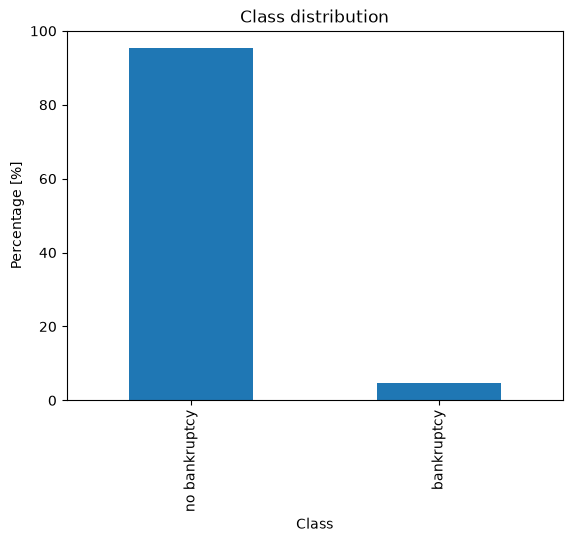

In [6]:
ax = class_pct.rename({0: "no bankruptcy", 1: "bankruptcy"}).plot.bar()
ax.set_title("Class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage [%]")
plt.show()


In [7]:
assert n_duplicates == 87
assert len(df) == 10416
assert "class" not in df.columns
assert len(y) == len(df)

assert 95 < class_pct[0] < 96
assert 4.5 < class_pct[1] < 5

print("Solution is correct!")

Solution is correct!


### Klasyfikacja niezbalansowana

Bankrutuje mniej niż 5% firm. Taki problem nazywamy **klasyfikacją niezbalansowaną (imbalanced classification)**. Mamy tu **klasę większościową (majority class)** oraz **klasę mniejszościową (minority class)**. Niestety prawie zawsze interesuje nas właśnie ta druga. 

Przykłady takich problemów to np. wykrywanie oszustw (*fraud detection*), przewidywanie odejścia klientów (*churn prediction*), czy diagnostyka medyczna.

Klasyfikacja niezbalansowana jest bardzo częsta i trudniejsza od zbalansowanej. Jak zobaczymy, wymaga odpowiednich metryk, a także zmian w samych modelach.

### Wartości brakujące

Sprawdźmy teraz wartości brakujące.

In [8]:
missing_pct = df.isna().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

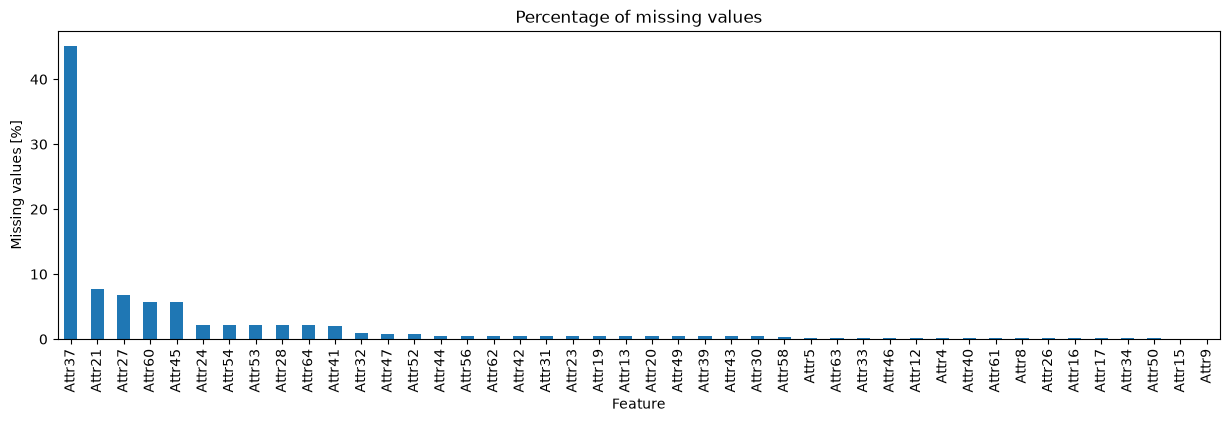

In [9]:
ax = missing_pct.plot.bar(figsize=(15, 4))
ax.set_title("Percentage of missing values")
ax.set_xlabel("Feature")
ax.set_ylabel("Missing values [%]")
plt.show()

Cecha `Attr37`, czyli `(current assets - inventories) / long-term liabilities`, nie ma wartości dla prawie połowy firm. Prawdopodobnie wiele firm po prostu nie ma zobowiązań długoterminowych, więc mianownik jest równy zero i wskaźnik jest niezdefiniowany.

Wartości brakujące nie zawsze oznaczają tylko brak informacji. Czasami sam fakt, że wartości brakuje, coś mówi - np. firma w złej kondycji może nie raportować części danych. Nazywa się to **informatywnymi wartościami brakującymi (informative missingness)**, albo **Missing Not At Random (MNAR)**.

Sprawdźmy, jaki odsetek firm bankrutuje, kiedy wartość jest obecna, a jaki, kiedy jej brakuje.

In [10]:
for col in ["Attr37", "Attr27", "Attr21"]:
    is_missing = df[col].isna()
    print(f"{col}: {feature_names[col]}")
    print(f"  bankruptcy rate, value present: {y[~is_missing].mean():.2%}")
    print(f"  bankruptcy rate, value missing: {y[is_missing].mean():.2%}")

Attr37: (current assets - inventories) / long-term liabilities
  bankruptcy rate, value present: 4.71%
  bankruptcy rate, value missing: 4.76%
Attr27: profit on operating activities / financial expenses
  bankruptcy rate, value present: 3.36%
  bankruptcy rate, value missing: 23.42%
Attr21: sales (n) / sales (n-1)
  bankruptcy rate, value present: 3.67%
  bankruptcy rate, value missing: 17.39%


W przypadku `Attr37` nie ma żadnej różnicy, a brakuje prawie połowy wartości, więc po prostu usuniemy tę cechę.

Natomiast dla `Attr27` (`profit on operating activities / financial expenses`) oraz `Attr21` (`sales (n) / sales (n-1)`) różnica jest ogromna - firmy z brakującą wartością bankrutują kilka razy częściej! Typowe uzupełnianie średnią czy medianą całkowicie zniszczyłoby tę informację, bo brakujące wartości stałyby się nieodróżnialne od typowych. Zapamiętaj to, przyda się później.

In [11]:
df = df.drop(columns="Attr37")

## Podział na zbiór treningowy i testowy

Podzielimy dane na zbiór treningowy (75%) i testowy (25%), tak jak w laboratorium 1. Przy klasyfikacji niezbalansowanej mamy jednak dodatkowy problem. Gdybyśmy dzielili dane całkowicie losowo, to proporcje klas w zbiorze treningowym i testowym mogłyby się wyraźnie różnić, bo klasy pozytywnej jest bardzo mało. W skrajnym przypadku w zbiorze testowym mogłoby jej w ogóle nie być!

Dlatego wykorzystuje się **stratyfikację (stratification)**. Dzięki temu proporcje klas w obu zbiorach są takie same, jak w całym zbiorze. W funkcji `train_test_split()` wystarczy przekazać wektor klas jako argument `stratify`. Stratyfikacja jest też domyślnie używana przez scikit-learn w walidacji skrośnej dla klasyfikacji.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.25, random_state=0, stratify=y
)

print(f"Training set: {len(X_train)} samples, {y_train.mean():.2%} bankruptcies")
print(f"Test set: {len(X_test)} samples, {y_test.mean():.2%} bankruptcies")
print(f"Bankruptcies in test set: {y_test.sum()}")

Training set: 7812 samples, 4.74% bankruptcies
Test set: 2604 samples, 4.72% bankruptcies
Bankruptcies in test set: 123


Zwróć uwagę, że w zbiorze testowym mamy tylko 123 bankructwa. To niewiele, więc metryki będą miały dość dużą wariancję - nie należy przywiązywać zbyt dużej wagi do niewielkich różnic między modelami.

## Metryki klasyfikacji

### Macierz pomyłek

W klasyfikacji binarnej możliwe są 4 sytuacje:
- **True Positive (TP)** - przewidujemy 1, prawdziwa klasa to 1 (wykryliśmy bankructwo)
- **True Negative (TN)** - przewidujemy 0, prawdziwa klasa to 0 (poprawnie uznaliśmy firmę za zdrową)
- **False Positive (FP)** - przewidujemy 1, prawdziwa klasa to 0 (fałszywy alarm, błąd I rodzaju)
- **False Negative (FN)** - przewidujemy 0, prawdziwa klasa to 1 (przeoczone bankructwo, błąd II rodzaju)

Chcemy oczywiście maksymalizować TP i TN, a minimalizować FP i FN. Wygodnie podsumowuje to **macierz pomyłek (confusion matrix)**:

| | przewidziane 0 | przewidziane 1 |
|---|---|---|
| **prawdziwe 0** | TN | FP |
| **prawdziwe 1** | FN | TP |

W scikit-learn macierz pomyłek oblicza funkcja [confusion_matrix()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), a rysuje klasa [ConfusionMatrixDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html).

### Accuracy, precision, recall, F1

Na podstawie macierzy pomyłek definiuje się szereg metryk:

- **dokładność (accuracy)** - jaki ułamek predykcji jest poprawny?
$$accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$
Jest to najbardziej intuicyjna metryka, ale jak zaraz zobaczymy, w klasyfikacji niezbalansowanej jest bardzo myląca.

- **precyzja (precision)** - jaki ułamek predykcji klasy 1 jest faktycznie klasą 1? Czy możemy ufać modelowi, kiedy twierdzi, że firma zbankrutuje? Przydatna, gdy fałszywe alarmy (FP) są dużo gorsze od przeoczeń (FN), np. w filtrach spamu.
$$precision = \frac{TP}{TP + FP}$$

- **czułość (recall)** - jaki ułamek przykładów klasy 1 wykryliśmy? Przydatna, gdy przeoczenia (FN) są dużo gorsze od fałszywych alarmów (FP), np. w diagnostyce medycznej czy wykrywaniu oszustw.
$$recall = \frac{TP}{TP + FN}$$

- **F1-score** - średnia harmoniczna precyzji i czułości; jest wysoka tylko wtedy, gdy obie są wysokie
$$F_1 = \frac{2 \cdot precision \cdot recall}{precision + recall}$$

Precyzji ani czułości nie można optymalizować osobno, np. przy doborze hiperparametrów. Maksymalną precyzję łatwo uzyskać, przewidując klasę 1 tylko dla jednego, najbardziej oczywistego przypadku. Maksymalną czułość daje z kolei przewidywanie zawsze klasy 1. Dlatego potrzebujemy pojedynczej liczby, która łączy obie metryki, czyli np. F1-score.

Bardzo dobre wyjaśnienie, z interaktywnymi wizualizacjami, znajdziesz [tutaj](https://mlu-explain.github.io/precision-recall/).

### Prawdopodobieństwa i próg klasyfikacji

Większość modeli klasyfikacji nie przewiduje bezpośrednio klas, tylko **prawdopodobieństwa (probabilities)** poszczególnych klas. Jest to dużo bardziej informatywne - "ta firma zbankrutuje" to coś zupełnie innego niż "ta firma zbankrutuje z prawdopodobieństwem 51%".

W klasyfikacji binarnej predykcję klasy uzyskujemy, stosując **próg (threshold)** dla prawdopodobieństwa klasy 1, domyślnie 50%. W klasyfikacji wieloklasowej po prostu wybieramy najbardziej prawdopodobną klasę.

W scikit-learn:
- `.predict_proba(X)` zwraca macierz prawdopodobieństw, z kolumną dla każdej klasy; prawdopodobieństwo klasy 1 to zatem `.predict_proba(X)[:, 1]`
- `.predict(X)` zwraca przewidziane klasy, czyli stosuje próg 50%

### ROC i AUROC

Metryki opisane powyżej oceniają model dla jednego, konkretnego progu. Można też ocenić model na podstawie samych prawdopodobieństw, biorąc pod uwagę wszystkie możliwe progi. Definiujemy:
- **True Positive Rate (TPR)** - to po prostu czułość, $TPR = \frac{TP}{TP + FN}$
- **False Positive Rate (FPR)** - jaki ułamek przykładów klasy 0 błędnie uznaliśmy za klasę 1, $FPR = \frac{FP}{FP + TN}$

**Krzywa ROC (Receiver Operating Characteristic)** pokazuje TPR względem FPR dla wszystkich możliwych progów. Pole pod tą krzywą to **AUROC (Area Under ROC)**, nazywane też AUC lub ROC AUC. Ma ono wartości:
- 0.5 dla klasyfikatora losowego
- 1.0 dla klasyfikatora idealnego

AUROC ma bardzo przyjemną interpretację: jest to prawdopodobieństwo, że model przypisze losowo wybranemu przykładowi klasy 1 wyższe prawdopodobieństwo niż losowo wybranemu przykładowi klasy 0. Mierzy zatem, jak dobrze model **szereguje (ranks)** przykłady. Nie zależy od progu i dobrze sprawdza się w klasyfikacji niezbalansowanej, dlatego jest bardzo popularną metryką.

Bardzo dobre wyjaśnienie, z interaktywnymi wizualizacjami, znajdziesz [tutaj](https://mlu-explain.github.io/roc-auc/).

**Uwaga:** AUROC oblicza się na podstawie **prawdopodobieństw**, a nie przewidzianych klas!

W scikit-learn wszystkie te metryki znajdują się w module `sklearn.metrics`: [accuracy_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), [precision_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html), [recall_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html), [f1_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) oraz [roc_auc_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html). Przyjmują one argumenty `(y_true, y_pred)`, a w przypadku AUROC `(y_true, y_proba)`.

### Model bazowy

Zanim zaczniemy trenować modele, warto stworzyć **model bazowy (baseline)**, czyli możliwie najprostszy model, który da nam punkt odniesienia. Każdy sensowny model musi być od niego lepszy. W scikit-learn najprostsze modele bazowe implementuje klasa [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html). Z argumentem `strategy="most_frequent"` zawsze przewiduje ona najczęstszą klasę ze zbioru treningowego.

### Zadanie 2 (1 punkt)

1. Zaimplementuj funkcję `evaluate_model()`:
    - oblicz prawdopodobieństwa klasy 1 dla zbioru treningowego i testowego,
    - oblicz przewidziane klasy dla zbioru testowego,
    - oblicz AUROC dla zbioru treningowego i testowego, a także precision, recall i F1-score dla zbioru testowego,
    - wypisz te metryki jako procenty, zaokrąglone do 2 miejsc po przecinku,
    - zwróć metryki jako słownik z kluczami `"train_auroc"`, `"test_auroc"`, `"precision"`, `"recall"` oraz `"f1"`.
2. Wytrenuj model `DummyClassifier` z `strategy="most_frequent"` w zmiennej `dummy` i dokonaj jego ewaluacji. Zapisz wyniki w słowniku `results`, pod kluczem `"Dummy"`. Wykorzystamy ten słownik później do porównania wszystkich modeli.

Jeżeli model nigdy nie przewiduje klasy 1, to precyzja jest niezdefiniowana (dzielimy przez zero). Przekaż wtedy `zero_division=0` do funkcji `precision_score()`, żeby uznać ją za 0 i uniknąć ostrzeżeń.

Skomentuj wyniki: jakie wartości metryk ma model bazowy? Dlaczego AUROC wynosi dokładnie 50%?

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_model(model, X_train, X_test, y_train, y_test) -> dict[str, float]:
    # probabilities of class 1
    y_proba_train = model.predict_proba(X_train)[:, 1]
    y_proba_test = model.predict_proba(X_test)[:, 1]

    # predicted classes
    y_pred_test = model.predict(X_test)

    metrics = {
        "train_auroc": roc_auc_score(y_train, y_proba_train),
        "test_auroc": roc_auc_score(y_test, y_proba_test),
        "precision": precision_score(y_test, y_pred_test, zero_division=0),
        "recall": recall_score(y_test, y_pred_test),
        "f1": f1_score(y_test, y_pred_test, zero_division=0),
    }

    print(f"Train AUROC: {metrics['train_auroc']:.2%}")
    print(f"Test AUROC: {metrics['test_auroc']:.2%}")
    print(f"Precision: {metrics['precision']:.2%}")
    print(f"Recall: {metrics['recall']:.2%}")
    print(f"F1-score: {metrics['f1']:.2%}")

    return metrics


results = {}

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
results["Dummy"] = evaluate_model(dummy, X_train, X_test, y_train, y_test)


Train AUROC: 50.00%
Test AUROC: 50.00%
Precision: 0.00%
Recall: 0.00%
F1-score: 0.00%


In [14]:
assert set(results["Dummy"].keys()) == {
    "train_auroc",
    "test_auroc",
    "precision",
    "recall",
    "f1",
}

assert results["Dummy"]["test_auroc"] == 0.5
assert results["Dummy"]["precision"] == 0
assert results["Dummy"]["recall"] == 0
assert results["Dummy"]["f1"] == 0

print("Solution is correct!")

Solution is correct!


Dummy zawsze mówi "brak bankructwa". Precyzja, czułość i F1 są równe 0%, bo model ani razu nie wskazuje klasy 1. AUROC na treningu i na teście wynosi dokładnie 50%. Każda firma dostaje to samo prawdopodobieństwo, więc bankrut nie ląduje wyżej niż zdrowa firma. To ten sam wynik co losowe szeregowanie.


### Dlaczego nie accuracy?

Funkcja `evaluate_model()` celowo nie oblicza dokładności (accuracy). Zobaczmy, dlaczego - obliczmy ją dla modelu bazowego.

In [15]:
from sklearn.metrics import accuracy_score

dummy_accuracy = accuracy_score(y_test, dummy.predict(X_test))
print(f"Dummy accuracy: {dummy_accuracy:.2%}")

Dummy accuracy: 95.28%


Model, który nigdy nie przewiduje bankructwa, czyli jest kompletnie bezużyteczny, ma dokładność ponad 95% W klasyfikacji niezbalansowanej accuracy jest zdominowane przez klasę większościową, więc wysoki wynik nie mówi nic o tym, czy model wykrywa przykłady klasy mniejszościowej, a to właśnie nas interesuje. Co gorsza, model, który faktycznie wykrywa bankructwa, ale kosztem pewnej liczby fałszywych alarmów, będzie miał niższe accuracy niż ten bezużyteczny model bazowy. Dlatego w tym laboratorium w ogóle nie będziemy raportować accuracy, a jedynie AUROC, precyzję, czułość oraz F1-score.

## Regresja logistyczna

### Model

**Regresja logistyczna (logistic regression)** to model klasyfikacji binarnej, oparty o regresję liniową. Wynik kombinacji liniowej $w^Tx$ ma wartości z zakresu $(-\infty, +\infty)$, więc przekształcamy go **funkcją sigmoidalną (sigmoid function)**, nazywaną też funkcją logistyczną, do zakresu $[0, 1]$:
$$
\hat{y} = \sigma(w^Tx) = \frac{1}{1 + e^{-w^Tx}}
$$

Wynik interpretujemy jako prawdopodobieństwo klasy pozytywnej $P(y = 1 | x)$. Granica decyzyjna to hiperpłaszczyzna $w^Tx = 0$, dla której prawdopodobieństwo wynosi dokładnie 50%. Im dalej od niej znajduje się punkt, tym pewniejszy jest model, czyli prawdopodobieństwo jest bliższe 0% lub 100%.

W przeciwieństwie do regresji liniowej nie ma tu rozwiązania analitycznego. Wagi wyznacza się numerycznie, minimalizując funkcję kosztu **binarnej entropii krzyżowej (binary cross-entropy, BCE)**, nazywanej też *log loss*:
$$
BCE(y, \hat{p}) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \right]
$$

Dla każdego przykładu "aktywuje się" tylko jeden z wyrazów, zależnie od prawdziwej klasy. Dla $y_i = 1$ chcemy, żeby $\hat{p}_i$ było bliskie 1, a dla $y_i = 0$ - bliskie 0. Duża pewność przy błędnej predykcji jest bardzo mocno penalizowana, bo $\log(x) \to -\infty$ dla $x \to 0$.

Regresja logistyczna jest szybka, prosta i interpretowalna, a do tego przewiduje dobrze **skalibrowane (calibrated)** prawdopodobieństwa. Jest jednak modelem liniowym, czyli ma dość małą pojemność. Dla wielu klas stosuje się jej rozszerzenie, czyli **regresję softmax (softmax regression)**, nazywaną też wielomianową (*multinomial*), które scikit-learn wykorzystuje automatycznie.

Dobre wyjaśnienie, z interaktywnymi wizualizacjami, znajdziesz [tutaj](https://mlu-explain.github.io/logistic-regression/).

### Regresja logistyczna w scikit-learn

Model implementuje klasa [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Ważne parametry:
- `C` - **odwrotność** siły regularyzacji, domyślnie 1.0; im mniejsze `C`, tym silniejsza regularyzacja (odwrotnie niż `alpha` w regresji ridge!), a `C=np.inf` oznacza brak regularyzacji
- `l1_ratio` - udział kary L1, domyślnie 0, czyli regularyzacja L2; 1 oznacza regularyzację L1, a wartości pomiędzy - ElasticNet
- `solver` - algorytm optymalizacji; domyślny `"lbfgs"` jest szybki i stabilny dla regularyzacji L2, ale L1 i ElasticNet wymagają solwera `"saga"`
- `max_iter` - maksymalna liczba iteracji solwera; ostrzeżenie o braku zbieżności (*convergence warning*) oznacza, że trzeba ją zwiększyć
- `class_weight` - wagi klas, omówione poniżej

Będziemy korzystać z solwera `"newton-cholesky"`. Jest to metoda Newtona, czyli metoda drugiego rzędu, korzystająca z hesjanu funkcji kosztu. Dla zbiorów z dużą liczbą próbek i niewielką liczbą cech (do kilkuset), czyli takich jak nasze, zbiega w kilka iteracji. Jest w takich przypadkach dużo szybsza od `"lbfgs"`, który jako metoda quasi-Newtonowska estymuje przybliżenie hesjanu z pomocą pierwszej pochodnej. Kroki takiego algorytmu są szybsze, ale wymaga tu setek iteracji, co sumarycznie jest wolniejsze.

Regresja logistyczna, jak wszystkie modele liniowe, wymaga przeskalowanych cech. Nie obsługuje też wartości brakujących. Potrzebujemy zatem imputacji i skalowania, tak jak w laboratorium 1.

### Pipeline'y

W laboratorium 1 wykonywaliśmy kolejne transformacje ręcznie, wywołując `.fit()` i `.transform()` dla zbioru treningowego i testowego. Jest to sporo powtarzalnego kodu, a do tego łatwo o błąd, np. przetworzenie danych treningowych i testowych w niespójny sposób (*train-test skew*) albo przypadkowe wywołanie `.fit()` na danych testowych.

Scikit-learn rozwiązuje ten problem za pomocą klasy [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), która łączy kolejne kroki przetwarzania oraz model w jeden obiekt. Używa się go dokładnie jak modelu:
- `.fit(X_train, y_train)` - po kolei trenuje każdą transformację (`.fit_transform()`) i przekazuje jej wynik do kolejnego kroku, a na końcu trenuje model
- `.predict(X)` i `.predict_proba(X)` - po kolei przekształca dane (`.transform()`) wytrenowanymi transformacjami i zwraca predykcje modelu

Dzięki temu cały proces przetwarzania jest zamknięty w jednym obiekcie, który przyjmuje surowe dane. Pipeline'y działają też poprawnie z walidacją skrośną, np. w `GridSearchCV` - transformacje są trenowane osobno w każdym foldzie, tylko na jego danych treningowych, więc nie ma wycieku danych.

Najwygodniej tworzyć je funkcją [make_pipeline()](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html), która automatycznie nadaje krokom nazwy na podstawie nazw klas, np. `"standardscaler"`. Do poszczególnych kroków odwołujemy się przez indeks, np. `pipeline[-1]` to ostatni krok (model), albo przez nazwę, np. `pipeline.named_steps["standardscaler"]`.

Zbudujmy pipeline z regresją logistyczną. Do imputacji używamy mediany, bo średnia byłaby kompletnie zaburzona przez wartości odstające.

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

log_reg = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(solver="newton-cholesky"),
)
log_reg.fit(X_train, y_train)

results["Logistic regression"] = evaluate_model(
    log_reg, X_train, X_test, y_train, y_test
)

Train AUROC: 72.80%
Test AUROC: 65.22%
Precision: 12.50%
Recall: 0.81%
F1-score: 1.53%


Regresja logistyczna jest lepsza od modelu bazowego, ale niewiele. Co gorsza, czułość jest bliska zeru - model praktycznie nigdy nie przewiduje bankructwa! Mamy tutaj dwa problemy:
1. **Niezbalansowanie klas** - klasa 0 dominuje funkcję kosztu, więc modelowi "opłaca się" przewidywać niskie prawdopodobieństwa bankructwa dla wszystkich firm.
2. **Wartości odstające** - `StandardScaler` korzysta ze średniej i odchylenia standardowego, które są kompletnie zaburzone przez ekstremalne wartości. Po skalowaniu prawie wszystkie firmy mają wartości bardzo bliskie 0, a tylko kilka skrajnych przypadków ma ogromne wartości.

Zajmijmy się po kolei oboma problemami.

### Ważenie klas

Zwróć uwagę, że w funkcji kosztu BCE sumujemy błędy po wszystkich przykładach. Jeżeli klasa 1 to niecałe 5% przykładów, to ma ona też bardzo mały wpływ na wartość funkcji kosztu. Ten sam problem dotyczy praktycznie wszystkich algorytmów ML.

Najprostszym rozwiązaniem jest **ważenie klas (class weighting)**. Błędy dla każdej klasy mnożymy przez jej wagę $w_k$, więc pomyłki dla rzadkiej klasy z dużą wagą są mocniej penalizowane. W scikit-learn w zasadzie każdy klasyfikator ma parametr `class_weight`. Wagi można podać ręcznie jako słownik, albo użyć `class_weight="balanced"`, gdzie wagi są odwrotnie proporcjonalne do liczności klas:
$$
w_k = \frac{N}{K \cdot N_k}
$$
gdzie $N$ to liczba przykładów, $K$ to liczba klas, a $N_k$ to liczba przykładów klasy $k$. Dzięki temu obie klasy mają łącznie taki sam wpływ na funkcję kosztu. Zobaczmy, jakie wagi otrzymamy dla naszego zbioru.

In [17]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
print(f"Class weights: {class_weights.round(2)}")

Class weights: [ 0.52 10.56]


Błędy dla bankrutujących firm będą zatem ważyły ok. 20 razy więcej niż dla pozostałych. W ogólności wagi klas to hiperparametry i można je dobierać, ale `"balanced"` jest bardzo dobrym punktem wyjścia.

Wytrenujmy regresję logistyczną z ważeniem klas i porównajmy ją z poprzednim modelem.

In [18]:
log_reg_balanced = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", solver="newton-cholesky"),
)
log_reg_balanced.fit(X_train, y_train)

results["LR balanced"] = evaluate_model(
    log_reg_balanced, X_train, X_test, y_train, y_test
)

Train AUROC: 77.27%
Test AUROC: 68.24%
Precision: 8.98%
Recall: 65.04%
F1-score: 15.78%


Czułość wzrosła z ok. 1% do ok. 65%, czyli model wykrywa teraz prawie 2/3 bankructw. Kosztem jest bardzo niska precyzja - tylko co jedenasty alarm jest trafny. AUROC wzrósł natomiast tylko nieznacznie. Ważenie klas głównie przesuwa przewidywane prawdopodobieństwa klasy 1 w górę, przez co więcej firm przekracza próg 50%, ale w niewielkim stopniu zmienia kolejność firm, a właśnie ją mierzy AUROC.

Najlepiej widać to na macierzach pomyłek. Funkcja [ConfusionMatrixDisplay.from_estimator()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_estimator) sama oblicza predykcje modelu i rysuje macierz, a argument `ax` pozwala narysować ją na konkretnym wykresie.

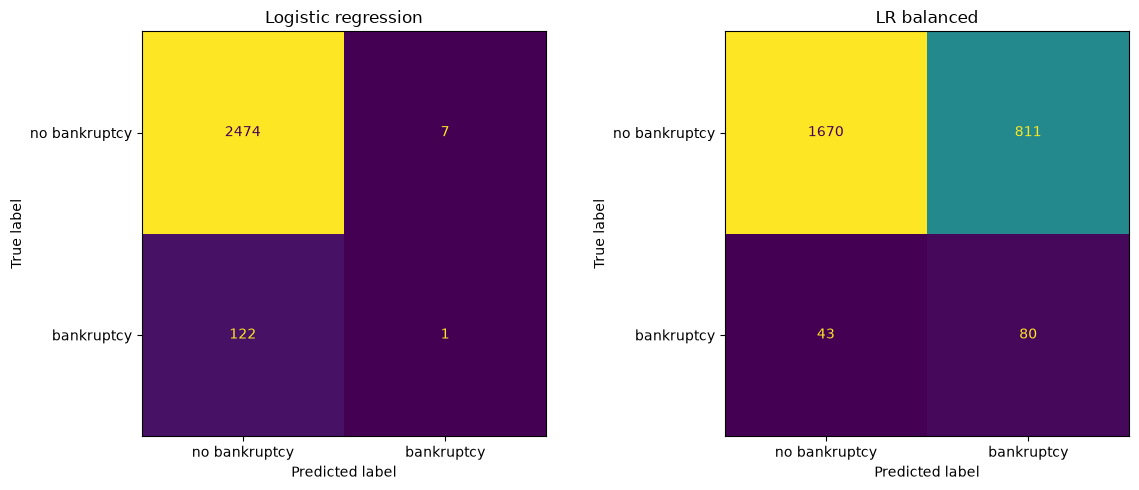

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in [
    (axes[0], log_reg, "Logistic regression"),
    (axes[1], log_reg_balanced, "LR balanced"),
]:
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["no bankruptcy", "bankruptcy"],
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

Model bez ważenia klas wykrył tylko 1 ze 123 bankructw - jest praktycznie bezużyteczny. Model z ważeniem klas wykrywa ich 80, ale kosztem ponad 800 fałszywych alarmów. To, który model jest lepszy, zależy od kosztów obu rodzajów błędów. Dla banku przeoczone bankructwo oznacza zwykle utratę całego kredytu, a fałszywy alarm - utratę zysku z jednego klienta, więc wolałby raczej drugi model. Jak zobaczymy później, ten kompromis można jeszcze regulować progiem decyzyjnym.

### Winsoryzacja

W laboratorium 1 radziliśmy sobie z wartościami odstającymi za pomocą **winsoryzacji (winsorization)**, czyli przycinania wartości cechy do wybranych percentyli, obliczonych na zbiorze treningowym. Tutaj problem jest jednak dużo poważniejszy, bo wartości odstające są skrajne i występują dla prawie wszystkich cech. Po standaryzacji surowych danych największe wartości cech sięgają prawie 90, czyli pojedyncze firmy leżą 90 odchyleń standardowych od średniej! Dlatego przytniemy wszystkie cechy, a nie tylko wybrane.

Ponownie wykorzystamy klasę [Winsorizer](https://feature-engine.trainindata.com/en/latest/api_doc/outliers/Winsorizer.html) z biblioteki Feature-engine. Jeżeli nie podamy parametru `variables`, to przycina ona wszystkie cechy numeryczne. Argument `missing_values="ignore"` pozwala pominąć wartości brakujące przy obliczaniu percentyli.

Winsoryzacja jest **transformacją monotoniczną (monotonic transformation)**, czyli nie zmienia kolejności wartości. Jest to ważne, bo nie zmienia relacji między firmami - firma z wyższym zadłużeniem dalej ma wyższą (albo, po przycięciu, taką samą) wartość cechy, tylko skrajne różnice zostają spłaszczone.

Zobaczmy, jak wygląda przykładowa cecha `Attr5` po winsoryzacji do 1. i 99. percentyla, tak jak w laboratorium 1, oraz po mocniejszej winsoryzacji, do 5. i 95. percentyla.

In [20]:
from feature_engine.outliers import Winsorizer

col = "Attr5"
X_col = X_train[[col]].dropna()

transformed = {"original": X_col}
for fold in [0.01, 0.05]:
    winsorizer = Winsorizer(capping_method="quantiles", tail="both", fold=fold)
    transformed[f"winsorized to {fold:.0%}-{1 - fold:.0%}"] = winsorizer.fit_transform(
        X_col
    )

KeyError: 'market_segment'

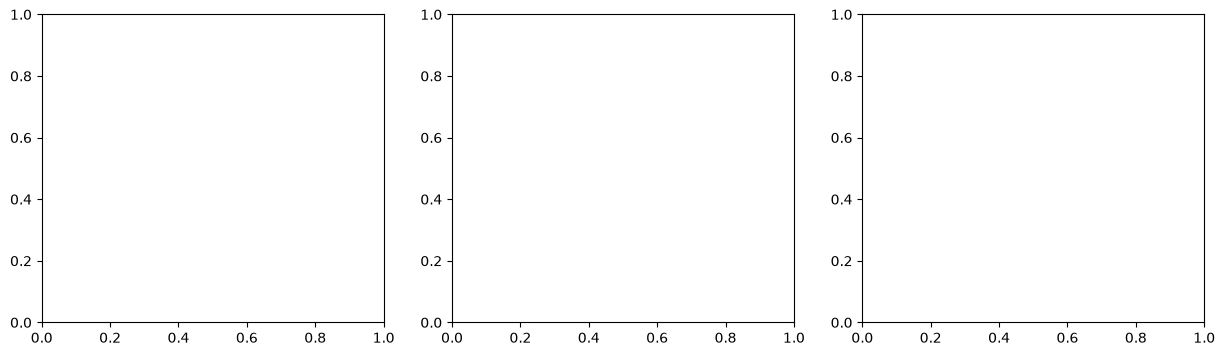

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, values) in zip(axes, transformed.items()):
    values[col].plot.hist(bins=50, ax=ax)
    ax.set_title(f"{col}, {name}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

Bez przetwarzania prawie wszystkie wartości znajdują się w jednym przedziale histogramu, a cała informacja o różnicach między typowymi firmami jest praktycznie niewidoczna dla modelu. Standaryzacja by tu nie pomogła, bo tylko przesuwa i skaluje wartości, nie zmieniając kształtu rozkładu. Winsoryzacja do 1. i 99. percentyla tutaj nie wystarcza - dalej mamy wartości rzędu tysięcy, przy medianie ok. 1.6. Dopiero mocniejsze przycięcie daje sensowny rozkład. Zwróć uwagę na "słupki" na obu krańcach - to właśnie przycięte wartości.

Dlatego przytniemy wszystkie cechy do 5. i 95. percentyla, czyli łącznie 10% wartości każdej cechy. To dużo więcej niż w laboratorium 1, ale też wartości odstających jest tu dużo więcej.

### Wskaźniki brakujących wartości

Pozostał jeszcze problem informatywnych wartości brakujących, które zauważyliśmy podczas EDA. Możemy zachować tę informację, dodając binarne **wskaźniki brakujących wartości (missing indicators)** - dla każdej cechy z brakami dodajemy nową cechę, która ma wartość 1, jeżeli wartości brakowało, i 0 w przeciwnym wypadku. W `SimpleImputer` wystarczy przekazać `add_indicator=True`.

### Zadanie 3 (0.5 punktu)

Stwórz dwa pipeline'y z regresją logistyczną z ważeniem klas, tak jak `log_reg_balanced`:
1. `log_reg_winsorized` - winsoryzacja wszystkich cech do 5. i 95. percentyla (`Winsorizer` z `capping_method="quantiles"`, `tail="both"`, `fold=0.05` oraz `missing_values="ignore"`), imputacja medianą, `StandardScaler`, regresja logistyczna; zapisz wyniki w `results` pod kluczem `"LR winsorized"`.
2. `log_reg_missing` - jak wyżej, ale z imputacją z dodaniem wskaźników brakujących wartości (`add_indicator=True`); zapisz wyniki pod kluczem `"LR winsorized + missing indicators"`.

Winsoryzacja musi być pierwszym krokiem pipeline'u. Po imputacji percentyle byłyby obliczane także z uzupełnionych wartości, a `Winsorizer` próbowałby przycinać binarne wskaźniki brakujących wartości (Feature-engine zgłosi wtedy błąd).

Skomentuj wyniki:
- Jak winsoryzacja i wskaźniki brakujących wartości wpłynęły na AUROC? Który z tych kroków dał większą poprawę?
- Jak zmieniły się precyzja i czułość względem modelu `log_reg_balanced`?

In [22]:
log_reg_winsorized = make_pipeline(
    Winsorizer(
        capping_method="quantiles",
        tail="both",
        fold=0.05,
        missing_values="ignore",
    ),
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", solver="newton-cholesky"),
)
log_reg_winsorized.fit(X_train, y_train)
print("LR winsorized")
results["LR winsorized"] = evaluate_model(
    log_reg_winsorized, X_train, X_test, y_train, y_test
)
print()

log_reg_missing = make_pipeline(
    Winsorizer(
        capping_method="quantiles",
        tail="both",
        fold=0.05,
        missing_values="ignore",
    ),
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", solver="newton-cholesky"),
)
log_reg_missing.fit(X_train, y_train)
print("LR winsorized + missing indicators")
results["LR winsorized + missing indicators"] = evaluate_model(
    log_reg_missing, X_train, X_test, y_train, y_test
)


LR winsorized
Train AUROC: 82.55%
Test AUROC: 71.88%
Precision: 10.03%
Recall: 59.35%
F1-score: 17.16%

LR winsorized + missing indicators
Train AUROC: 92.27%
Test AUROC: 85.46%
Precision: 19.07%
Recall: 69.92%
F1-score: 29.97%


In [23]:
assert isinstance(log_reg_winsorized[0], Winsorizer)
assert log_reg_winsorized[0].fold == 0.05
assert 0.7 < results["LR winsorized"]["test_auroc"] < 0.8
assert results["LR winsorized"]["test_auroc"] > results["LR balanced"]["test_auroc"]

assert isinstance(log_reg_missing[0], Winsorizer)
assert results["LR winsorized + missing indicators"]["test_auroc"] > 0.83

# missing indicators are added as new features
assert log_reg_missing[:-1].transform(X_test).shape[1] > X_test.shape[1]

print("Solution is correct!")

Solution is correct!


Sama winsoryzacja podniosła test AUROC z 68,24% (LR balanced) do 71,88%. Wskaźniki braków dały wyraźnie więcej: test AUROC urósł do 85,46%. Precyzja po samej winsoryzacji prawie stoi (8,98% -> 10,03%), a czułość lekko spadła (65,04% -> 59,35%). Po dodaniu wskaźników precyzja jest 19,07%, a czułość 69,92%.

## Drzewa decyzyjne

### Model

**Drzewo decyzyjne (decision tree)** to model, który uczy się reguł postaci if/else, zorganizowanych w drzewo binarne:
- **węzły (nodes)** to podziały, z których każdy korzysta z jednej cechy i progu, np. "Attr27 <= 0.5?"
- **liście (leaves)** to decyzje, czyli przewidywane klasy

Predykcja polega na przejściu od korzenia do liścia. W każdym węźle porównujemy wartość cechy z progiem i idziemy do lewego albo prawego dziecka, aż dojdziemy do liścia. Każdy podział jest prostopadły do osi jednej cechy, ale ich sekwencja tworzy złożoną, nieliniową granicę decyzyjną.

Drzewo budowane jest zachłannym, rekurencyjnym algorytmem:
1. Zacznij od całego zbioru treningowego w korzeniu.
2. Dla każdej cechy i każdego możliwego progu podziel zbiór na lewe i prawe dziecko, a następnie oblicz wartość funkcji kosztu dla tego podziału.
3. Wybierz najlepszy podział, czyli o najniższym koszcie.
4. Powtórz rekurencyjnie dla obu dzieci, aż dostaniesz **czyste liście (pure leaves)**, czyli zawierające tylko jedną klasę.

Funkcja kosztu mierzy **nieczystość (impurity)** węzła, czyli to, jak bardzo wymieszane są w nim klasy. Dla podziału jest to średnia nieczystość obu dzieci, ważona liczbą przykładów w każdym z nich. Dobry podział rozdziela zatem klasy od siebie, i to dla dużej liczby przykładów. Typowe funkcje kosztu to:
- **entropia (entropy)**: $H = -\sum_{k=1}^K p_k \log_2 p_k$
- **indeks Giniego (Gini index)**: $G = 1 - \sum_{k=1}^K p_k^2$

gdzie $p_k$ to ułamek przykładów klasy $k$ w węźle. Obie mają wartość 0 dla czystego węzła i maksymalną dla równo wymieszanych klas. W praktyce dają bardzo podobne wyniki.

Doskonałe wyjaśnienie, z interaktywnymi wizualizacjami, znajdziesz [tutaj](https://mlu-explain.github.io/decision-tree/).

### Regularyzacja i przetwarzanie danych

Budowanie drzewa aż do czystych liści oznacza, że każdy przykład treningowy jest sklasyfikowany poprawnie, czyli idealne "zakucie" danych. Drzewa decyzyjne mają zatem bardzo niskie obciążenie (*bias*), ale bardzo wysoką wariancję (*variance*), i bardzo łatwo się przeuczają. Dlatego w praktyce wymagają regularyzacji, czyli ograniczenia podziałów. Najczęściej używane hiperparametry w [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) to:
- `max_depth` - maksymalna głębokość drzewa, czyli liczba podziałów na ścieżce od korzenia do liścia
- `min_samples_split` - minimalna liczba przykładów w węźle, żeby rozważać jego podział
- `min_samples_leaf` - minimalna liczba przykładów w liściu

Po regularyzacji liście nie są czyste, więc przewidują najczęstszą klasę. Prawdopodobieństwo klasy to po prostu jej udział wśród przykładów treningowych w liściu.

Drzewa mają za to ogromną zaletę, jeżeli chodzi o przetwarzanie danych:
- **nie wymagają skalowania** - każdy podział korzysta z jednej cechy naraz, a liczy się tylko kolejność wartości, a nie ich skala
- **są odporne na wartości odstające** - z tego samego powodu; dla progu "Attr5 <= 2" nie ma znaczenia, czy największa wartość to 3, czy 3 miliony
- **obsługują wartości brakujące** - od wersji 1.3 drzewa w scikit-learn przy każdym podziale sprawdzają, czy lepiej wysłać przykłady z brakującą wartością do lewego, czy do prawego dziecka; dzięki temu mogą wykorzystać informatywne wartości brakujące

Możemy zatem użyć surowych danych, bez żadnego przetwarzania!

### Wizualizacja drzewa

Drzewa decyzyjne są bardzo **interpretowalne (interpretable)**, bo są po prostu zbiorem reguł if/else. Małe drzewo można łatwo narysować za pomocą funkcji [plot_tree()](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html). Korzysta ona tylko z matplotlib, więc nie wymaga instalowania żadnych dodatkowych programów. Przydatne argumenty:
- `feature_names` - nazwy cech, żeby podziały były czytelne
- `class_names` - nazwy klas
- `filled=True` - kolorowanie węzłów według przeważającej klasy
- `impurity=False` - ukrycie wartości funkcji kosztu w węzłach, dla czytelności
- `proportion=True` - pokazywanie udziałów klas w węzłach zamiast liczby przykładów
- `ax` - wykres, na którym rysujemy; drzewa wymagają sporo miejsca, więc warto stworzyć duży wykres, np. `plt.subplots(figsize=(20, 8))`

Istnieje też funkcja [export_text()](https://scikit-learn.org/stable/modules/generated/sklearn.tree.export_text.html), która wypisuje drzewo jako tekst.

**Uwaga:** jeżeli podział ma próg `inf` (nieskończoność), np. "Attr27 <= inf", to jest to podział względem brakujących wartości. Przykłady z obecną wartością idą do lewego dziecka, a z brakującą - do prawego.

### Drzewo bez regularyzacji

Zobaczmy najpierw, jak działa drzewo bez żadnej regularyzacji, czyli budowane aż do czystych liści. Metody `.get_depth()` oraz `.get_n_leaves()` zwracają głębokość drzewa i liczbę liści.

In [24]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)

results["Decision tree"] = evaluate_model(tree, X_train, X_test, y_train, y_test)
print(f"Depth: {tree.get_depth()}, leaves: {tree.get_n_leaves()}")

Train AUROC: 100.00%
Test AUROC: 67.15%
Precision: 37.40%
Recall: 37.40%
F1-score: 37.40%
Depth: 26, leaves: 237


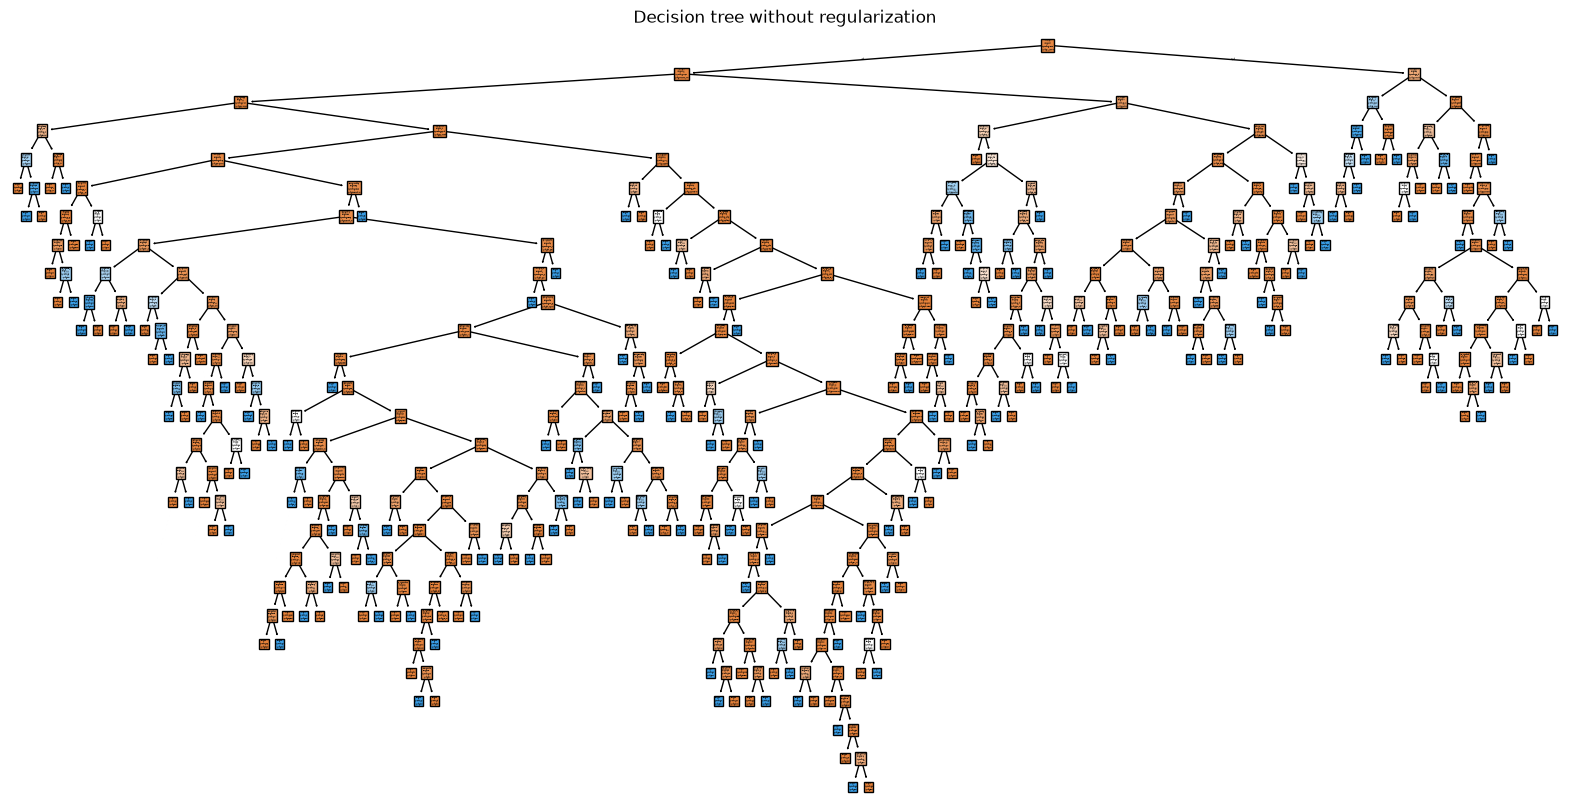

In [25]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree, filled=True, ax=ax)
ax.set_title("Decision tree without regularization")
plt.show()

Drzewo idealnie dopasowało się do zbioru treningowego (AUROC 100%), ale na zbiorze testowym jest gorsze od regresji logistycznej z ważeniem klas. Jest to klasyczne przeuczenie - drzewo ma kilkadziesiąt poziomów i ponad 200 liści, więc praktycznie zapamiętało zbiór treningowy, łącznie z szumem. Zwróć uwagę, że część liści zawiera pojedyncze firmy. Rysunek jest zupełnie nieczytelny - takie drzewo to setki reguł, z których wiele opisuje pojedyncze firmy, więc nie da się go sensownie zinterpretować.

### Zadanie 4 (1 punkt)

1. Dokonaj tuningu regularyzacji drzewa decyzyjnego (`random_state=0`) za pomocą `GridSearchCV` w zmiennej `tree_grid`. Sprawdź wartości `max_depth` ze zbioru `[2, 3, 4, 5, 6]` oraz `min_samples_leaf` ze zbioru `[10, 25, 50, 100, 200]`. Ograniczamy się do płytkich drzew, żeby najlepsze drzewo dało się narysować i zinterpretować. Użyj `scoring="roc_auc"`, `cv=5` oraz `n_jobs=-1`. Wypisz najlepsze hiperparametry, dokonaj ewaluacji i zapisz wyniki w `results` pod kluczem `"Decision tree tuned"`. Wypisz głębokość i liczbę liści najlepszego drzewa (`.best_estimator_`).
2. Narysuj najlepsze drzewo za pomocą `plot_tree()`. Użyj czytelnych nazw cech i klas.

Skomentuj wyniki:
- Jak regularyzacja zmieniła rozmiar drzewa i wyniki? Czy drzewo dalej jest przeuczone?
- Porównaj drzewo po tuningu z regresją logistyczną. Ile pracy włożyliśmy w przygotowanie danych dla każdego z tych modeli?
- Jakie reguły zawiera drzewo? Czy mają sens? Który liść ma największy udział bankructw?

Podpowiedź: czytelne nazwy cech możesz uzyskać za pomocą `X_train.columns.map(feature_names)`.

In [26]:
from sklearn.model_selection import GridSearchCV

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid={
        "max_depth": [2, 3, 4, 5, 6],
        "min_samples_leaf": [10, 25, 50, 100, 200],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
tree_grid.fit(X_train, y_train)
print(tree_grid.best_params_)
results["Decision tree tuned"] = evaluate_model(
    tree_grid, X_train, X_test, y_train, y_test
)

best_tree = tree_grid.best_estimator_
print(f"Depth: {best_tree.get_depth()}, leaves: {best_tree.get_n_leaves()}")


{'max_depth': 5, 'min_samples_leaf': 200}
Train AUROC: 88.53%
Test AUROC: 81.61%
Precision: 52.38%
Recall: 26.83%
F1-score: 35.48%
Depth: 5, leaves: 11


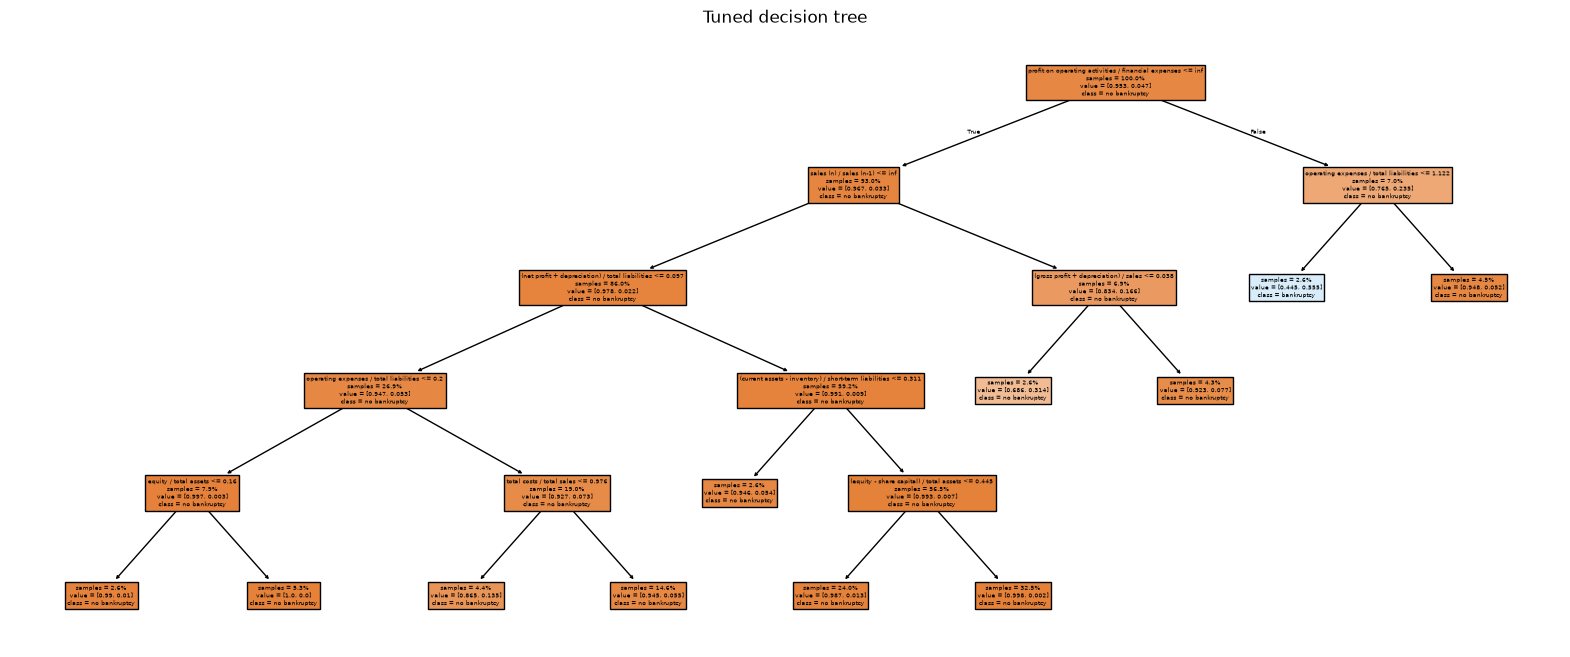

In [27]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    best_tree,
    feature_names=X_train.columns.map(feature_names),
    class_names=["no bankruptcy", "bankruptcy"],
    filled=True,
    impurity=False,
    proportion=True,
    ax=ax,
)
ax.set_title("Tuned decision tree")
plt.show()


In [28]:
assert tree_grid.best_params_["max_depth"] in [2, 3, 4, 5, 6]
assert results["Decision tree tuned"]["test_auroc"] > 0.75
assert (
    results["Decision tree tuned"]["test_auroc"]
    > results["Decision tree"]["test_auroc"]
)
assert best_tree.get_n_leaves() < tree.get_n_leaves()

print("Solution is correct!")

Solution is correct!


Bez regularyzacji drzewo miało głębokość 26 i 237 liści, AUROC 100% na treningu i 67,15% na teście. Po tuningu zostaje max_depth=5 i min_samples_leaf=200, czyli 11 liści. Trening spada do 88,53%, test rośnie do 81,61%. Luka między treningiem a testem jest dużo mniejsza, więc to już nie jest takie zapamiętanie danych jak wcześniej.

Regresja doszła do 85,46% dopiero po winsoryzacji, skalowaniu i wskaźnikach braków. Drzewo bierze surowe kolumny i wystarczyło dobrać dwa parametry. Wynik jest trochę słabszy niż ta regresja, ale przygotowania danych było dużo mniej.

Pierwszy podział to Attr27 <= inf. Próg inf oznacza brak wartości, a Attr27 to zysk z działalności operacyjnej podzielony przez koszty finansowe. Jak Attr27 brakuje i Attr34 <= 1,122 (koszty operacyjne / zobowiązania), w liściu jest 55,5% bankructw (111 z 200). To najwyższy udział. Jak brakuje Attr21 (sprzedaż rok do roku), a Attr13 jest niskie, bankrutuje 31,37%. Tam, gdzie Attr27 i Attr21 są uzupełnione, udział bankructw spada do kilku procent albo do zera. To pasuje do tego, co wyszło przy brakach: firmy bez Attr27 i Attr21 bankrutowały kilka razy częściej, i drzewo właśnie z tego korzysta.

## Random Forest

### Uczenie zespołowe

Drzewa decyzyjne praktycznie nigdy nie są używane pojedynczo, tylko w zespołach. **Uczenie zespołowe (ensemble learning)** polega na łączeniu wielu modeli w jeden, silniejszy model. Najważniejsze podejścia to:
- **bagging** - trenujemy wiele modeli równolegle, na lekko różniących się wersjach zbioru treningowego, i uśredniamy ich predykcje; zmniejsza to wariancję
- **boosting** - trenujemy modele sekwencyjnie, a każdy kolejny poprawia błędy poprzednich; zmniejsza to obciążenie i wariancję
- **uśrednianie (model averaging, voting)** - trenujemy kilka różnych modeli na tych samych danych i uśredniamy ich predykcje
- **stacking** - trenujemy kilka modeli, a następnie dodatkowy model, który uczy się łączyć ich predykcje

Drzewa są idealnymi modelami bazowymi do zespołów, bo są szybkie, a do tego mają niskie obciążenie i wysoką wariancję. Uśrednianie bardzo skutecznie zmniejsza tę wariancję.

### Model

**Las losowy (Random Forest, RF)** to zespół drzew decyzyjnych, wykorzystujący bagging oraz losowanie cech:
1. **Bagging (bootstrap aggregation)** - dla każdego drzewa losujemy **próbkę bootstrapową (bootstrap sample)**, czyli $N$ przykładów **ze zwracaniem** ze zbioru treningowego o $N$ przykładach. Część przykładów się powtarza, a średnio ok. 37% nie zostaje wylosowanych wcale. Każde drzewo widzi zatem nieco inny zbiór danych.
2. **Losowanie cech (feature subsampling)** - przy każdym podziale drzewo może wybrać tylko spośród losowego podzbioru cech, typowo $\sqrt{D}$ dla $D$ cech. Bez tego wszystkie drzewa wybierałyby te same najsilniejsze cechy blisko korzenia, więc byłyby bardzo podobne, a uśrednianie podobnych modeli niewiele daje. Losowanie cech zwiększa **różnorodność (diversity)** zespołu.
3. **Agregacja** - predykcja lasu to średnia prawdopodobieństw ze wszystkich drzew.

Drzewa w lesie zwykle nie są regularyzowane, bo bagging i losowanie cech same w sobie bardzo dobrze zapobiegają przeuczeniu. Random Forest jest mało czuły na wartości hiperparametrów, więc ma niską **podatność na tuning (tunability)**. Z jednej strony zwykle nie trzeba go tunować, a z drugiej strony niewiele zyskujemy, nawet jeżeli możemy sobie na to pozwolić. Drzewa są trenowane niezależnie od siebie, więc trening jest w pełni równoległy (*embarassingly parallel*). Jest to zatem doskonały domyślny wybór dla danych tabelarycznych.

W scikit-learn model implementuje klasa [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). Ważne parametry:
- `n_estimators` - liczba drzew; więcej drzew praktycznie zawsze poprawia wyniki, ale z malejącymi zyskami, a rośnie koszt obliczeniowy; zwykle wystarcza 500-1000 drzew
- `max_features` - rozmiar losowanego podzbioru cech, domyślnie `"sqrt"`
- `n_jobs` - liczba równoległych procesów; `-1` oznacza użycie wszystkich rdzeni procesora
- `class_weight` - wagi klas; wariant `"balanced_subsample"` oblicza wagi osobno dla każdej próbki bootstrapowej
- hiperparametry regularyzacji pojedynczych drzew, np. `min_samples_leaf`

Tak jak pojedyncze drzewa, Random Forest w scikit-learn obsługuje wartości brakujące i nie wymaga skalowania ani radzenia sobie z wartościami odstającymi.

Dobre wyjaśnienie, z interaktywnymi wizualizacjami, znajdziesz [tutaj](https://mlu-explain.github.io/random-forest/).

### Zadanie 5 (0.5 punktu)

1. Wytrenuj model Random Forest z 500 drzewami w zmiennej `rf`, na surowych danych. Użyj `n_jobs=-1` oraz `random_state=0`. Dokonaj ewaluacji i zapisz wyniki w `results` pod kluczem `"Random Forest"`.
2. Wytrenuj taki sam model, ale z ważeniem klas `class_weight="balanced_subsample"`, w zmiennej `rf_balanced`. Zapisz wyniki pod kluczem `"Random Forest balanced"`.

Skomentuj wyniki:
- Jak Random Forest wypada na tle pojedynczego drzewa decyzyjnego?
- AUROC na zbiorze treningowym wynosi 100%. Czy oznacza to przeuczenie, biorąc pod uwagę wynik na zbiorze testowym?
- Jak ważenie klas wpłynęło na precyzję, czułość i F1-score? Porównaj to z efektem ważenia klas w regresji logistycznej.

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
results["Random Forest"] = evaluate_model(rf, X_train, X_test, y_train, y_test)

rf_balanced = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=0,
)
rf_balanced.fit(X_train, y_train)
results["Random Forest balanced"] = evaluate_model(
    rf_balanced, X_train, X_test, y_train, y_test
)


Train AUROC: 100.00%
Test AUROC: 84.45%
Precision: 75.00%
Recall: 17.07%
F1-score: 27.81%
Train AUROC: 100.00%
Test AUROC: 85.48%
Precision: 75.00%
Recall: 12.20%
F1-score: 20.98%


In [30]:
assert results["Random Forest"]["test_auroc"] > 0.8
assert (
    results["Random Forest"]["test_auroc"]
    > results["Decision tree tuned"]["test_auroc"]
)
assert results["Random Forest balanced"]["test_auroc"] > 0.8

print("Solution is correct!")

Solution is correct!


Las jest lepszy od jednego drzewa. Test AUROC wynosi 84,45%, przy 81,61% dla drzewa po tuningu i 67,15% bez tuningu. Przy progu 50% czułość jest niska (17,07%), a precyzja wysoka (75,00%).

AUROC 100% na treningu nie znaczy, że las jest do wyrzucenia. Na teście zostaje 84,45%, czyli nadal powyżej pojedynczego drzewa. Różnica train-test jest duża, więc część dopasowania to zapamiętanie próbek, ale średnia z drzew działa na nowych firmach.

Ważenie klas zostawiło precyzję na 75,00%, a obniżyło czułość (17,07% -> 12,20%) i F1 (27,81% -> 20,98%). AUROC prawie stoi w miejscu (84,45% -> 85,48%). W regresji logistycznej te same wagi podniosły czułość z 0,81% do 65,04% i zbiły precyzję. Tutaj przy progu 50% model z wagami wykrywa mniej bankructw, a nie więcej.

### Ile drzew?

Jak wspomnieliśmy, więcej drzew prawie zawsze poprawia wyniki, ale z malejącymi zyskami. Sprawdźmy to. Moglibyśmy wykorzystać do tego walidację skrośną, ale Random Forest ma bardzo przydatną własność. Każde drzewo nie widzi średnio ok. 37% przykładów, czyli tych spoza jego próbki bootstrapowej. Są to przykłady **out-of-bag (OOB)**. Dla każdego przykładu możemy zatem uśrednić predykcje tylko tych drzew, które go nie widziały, i dostać w ten sposób predykcje "walidacyjne" za darmo, bez dodatkowego treningu. Z argumentem `oob_score=True` las zapisuje takie prawdopodobieństwa w atrybucie `.oob_decision_function_`.

Wykorzystamy też argument `warm_start=True`, dzięki któremu po zwiększeniu `n_estimators` kolejne wywołanie `.fit()` dotrenowuje tylko nowe drzewa, zamiast trenować cały las od nowa.

In [31]:
import warnings

rf_oob = RandomForestClassifier(
    oob_score=True, warm_start=True, n_jobs=-1, random_state=0
)
n_trees_list = [25, 50, 100, 200, 300, 500, 750, 1000]
oob_auroc = []

with warnings.catch_warnings():
    # with few trees, some samples may not have OOB predictions yet
    warnings.simplefilter("ignore", UserWarning)
    for n_trees in n_trees_list:
        rf_oob.set_params(n_estimators=n_trees)
        rf_oob.fit(X_train, y_train)
        oob_auroc.append(roc_auc_score(y_train, rf_oob.oob_decision_function_[:, 1]))

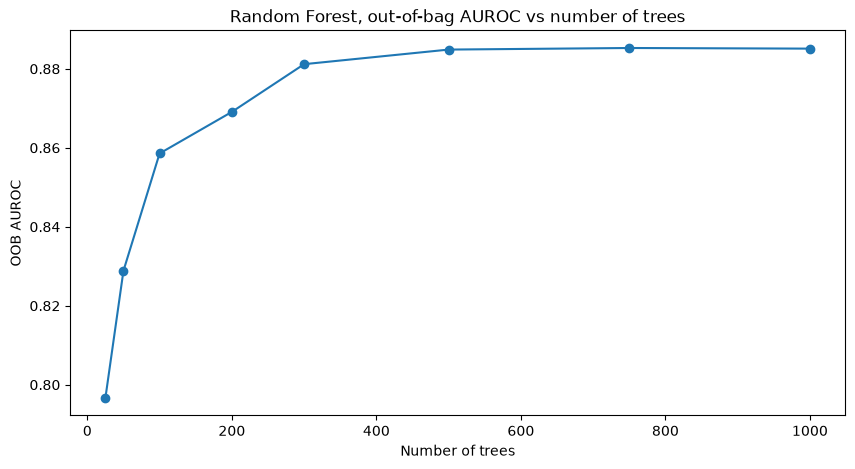

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_trees_list, oob_auroc, marker="o")
ax.set_title("Random Forest, out-of-bag AUROC vs number of trees")
ax.set_xlabel("Number of trees")
ax.set_ylabel("OOB AUROC")
plt.show()

Na początku wynik szybko rośnie, ale powyżej ok. 500 drzew już praktycznie się nie zmienia. Dodatkowe drzewa są coraz bardziej skorelowane z poprzednimi, więc uśrednianie coraz mniej zmniejsza wariancję. Dlatego zwykle po prostu ustawia się odpowiednio dużą liczbę drzew i nie tunuje się tego hiperparametru.

## Boosting

### Model

**Boosting** to druga bardzo ważna grupa metod zespołowych. O ile Random Forest trenuje drzewa niezależnie i je uśrednia, o tyle boosting robi to **sekwencyjnie**. Trenujemy pierwsze drzewo, które popełnia błędy na części przykładów. Następne drzewo uczy się poprawiać właśnie te błędy, kolejne poprawia błędy dwóch poprzednich i tak dalej. Model "wzmacnia się" (*boosts*) krok po kroku.

Najważniejszą formą boostingu jest **gradient boosting**. Kolejne drzewa uczą się przewidywać ujemny gradient funkcji kosztu (np. BCE) względem aktualnych predykcji zespołu. Dla błędu średniokwadratowego w regresji są to po prostu rezydua, czyli $y - \hat{y}$ - każde drzewo uczy się przewidywać, o ile pomyliły się poprzednie. Predykcja to suma predykcji wszystkich drzew:
$$
F_M(x) = F_0(x) + \eta \sum_{m=1}^M f_m(x)
$$
gdzie $F_0$ to predykcja początkowa (np. logarytm szansy klasy 1 w całym zbiorze), $f_m$ to kolejne drzewa, a $\eta$ to **współczynnik uczenia (learning rate)**. Dla klasyfikacji wynik przekształcamy na prawdopodobieństwo funkcją sigmoidalną, tak jak w regresji logistycznej.

Współczynnik uczenia sprawia, że każde drzewo poprawia tylko część błędów, więc kolejne kroki są mniejsze i bardziej ostrożne. Mniejszy współczynnik uczenia wymaga więcej drzew, ale zwykle daje lepsze wyniki. W boostingu używa się zwykle dość małych drzew (np. o głębokości 3-8), czyli **słabych modeli (weak learners)**, bo duża liczba kolejnych drzew i tak daje modelowi bardzo dużą pojemność.

Boosting zmniejsza zarówno obciążenie, jak i wariancję, i dla danych tabelarycznych zwykle daje najlepsze wyniki spośród wszystkich algorytmów ML. Ma jednak też wady:
- bardzo łatwo się przeucza, bo kolejne drzewa mogą w końcu zacząć uczyć się szumu
- ma dużo hiperparametrów i jest dość czuły na ich wartości, więc wymaga tuningu
- trening jest sekwencyjny, więc nie da się go zrównoleglić na poziomie drzew (tylko wewnątrz budowy pojedynczego drzewa)


### Implementacje

Najważniejsze implementacje gradient boostingu to:
- [XGBoost](https://xgboost.readthedocs.io/en/stable/) (2014) - pierwsza bardzo wydajna i skalowalna implementacja, prawdziwy przełom w ML, przez lata wygrywająca większość konkursów na Kaggle
- [LightGBM](https://lightgbm.readthedocs.io/en/stable/) (2017, Microsoft) - jeszcze szybsza, m.in. dzięki operowaniu na histogramach wartości cech zamiast na surowych wartościach, oraz budowaniu drzew "liść po liściu" (*leaf-wise*)
- [CatBoost](https://catboost.ai/) (2017, Yandex) - wyspecjalizowana w obsłudze zmiennych kategorycznych
- [HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html) w scikit-learn - implementacja inspirowana LightGBM

My wykorzystamy LightGBM. Jest on kompatybilny ze scikit-learn, więc działa z pipeline'ami, `GridSearchCV` itp. Obsługuje natywnie wartości brakujące, a także zmienne kategoryczne, co wykorzystamy w drugiej części laboratorium.

Najważniejsze hiperparametry klasy [LGBMClassifier](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html):
- `n_estimators` - liczba drzew, czyli kroków boostingu
- `learning_rate` - współczynnik uczenia
- `num_leaves` - maksymalna liczba liści w drzewie, czyli rozmiar pojedynczych drzew
- `min_child_samples` - minimalna liczba przykładów w liściu
- `subsample` - ułamek przykładów losowanych dla każdego drzewa (bez zwracania); działa tylko z `subsample_freq > 0`
- `colsample_bytree` - ułamek cech losowanych dla każdego drzewa
- `reg_lambda`, `reg_alpha` - siła regularyzacji L2 i L1 wartości w liściach
- `verbose=-1` - wyłącza bardzo liczne logi LightGBM

Hiperparametry LightGBM są dobrze opisane w [dokumentacji](https://lightgbm.readthedocs.io/en/stable/Parameters.html), która ma też [przewodnik po tuningu](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html).

### Early stopping

Liczba drzew i współczynnik uczenia są ze sobą silnie powiązane. Za mało drzew oznacza niedouczenie, a za dużo - przeuczenie. Zamiast dobierać liczbę drzew za pomocą tuningu, można wykorzystać **wczesne zatrzymanie (early stopping)**. Ustawiamy bardzo dużą liczbę drzew i po każdym kroku boostingu sprawdzamy wartość funkcji kosztu na zbiorze walidacyjnym. Jeżeli nie poprawia się ona przez określoną liczbę kroków (*patience*), to przerywamy trening i wybieramy model z najlepszej iteracji. W LightGBM służy do tego callback [early_stopping()](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.early_stopping.html).

W tym laboratorium nie będziemy z niego korzystać. Mamy mało danych, a zbiór walidacyjny wydzielony ze zbioru treningowego zawierałby tylko ok. 70 bankructw, więc decyzja o zatrzymaniu treningu byłaby bardzo zaszumiona. Przy dużych zbiorach danych early stopping jest jednak standardem.

### Tuning hiperparametrów

Boosting ma dużo hiperparametrów, więc przeszukiwanie wszystkich kombinacji w `GridSearchCV` byłoby zbyt kosztowne. Zamiast tego można użyć **losowego przeszukiwania (random search)**, które sprawdza tylko zadaną liczbę losowych kombinacji. W scikit-learn implementuje je klasa [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), o API bardzo podobnym do `GridSearchCV`. Liczbę prób określa argument `n_iter`, a zamiast siatki `param_grid` przekazujemy `param_distributions`. Mogą to być listy wartości, ale także rozkłady prawdopodobieństwa z modułu `scipy.stats`, co jest bardzo wygodne dla hiperparametrów ciągłych:
- `randint(a, b)` - losowa liczba całkowita z przedziału $[a, b)$
- `uniform(a, b)` - rozkład jednostajny na przedziale $[a, a + b]$ (uwaga - drugi argument to szerokość przedziału!)
- `loguniform(a, b)` - rozkład jednostajny w skali logarytmicznej, idealny dla hiperparametrów takich jak współczynnik uczenia czy siła regularyzacji

Przy tuningu warto zwrócić uwagę na `n_jobs`. Jeżeli zarówno model, jak i `RandomizedSearchCV` korzystają ze wszystkich rdzeni, to tworzymy dużo więcej wątków niż rdzeni procesora, co bardzo spowalnia obliczenia (*oversubscription*). Dlatego ustawimy `n_jobs=1` w modelu, a `n_jobs=-1` w `RandomizedSearchCV`, trenując wiele modeli równolegle.

Wykorzystamy następującą przestrzeń hiperparametrów:

In [33]:
from scipy.stats import loguniform, randint, uniform

lgbm_param_distributions = {
    "n_estimators": randint(100, 1000),
    "learning_rate": loguniform(0.005, 0.3),
    "num_leaves": randint(4, 128),
    "min_child_samples": randint(5, 200),
    "subsample": uniform(0.5, 0.5),  # [0.5, 1.0]
    "colsample_bytree": uniform(0.1, 0.9),  # [0.1, 1.0]
}

### Zadanie 6 (1 punkt)

1. Wytrenuj model LightGBM z domyślnymi hiperparametrami w zmiennej `lgbm`, na surowych danych. Przekaż `random_state=0` oraz `verbose=-1`. Dokonaj ewaluacji i zapisz wyniki w `results` pod kluczem `"LightGBM"`.
2. Dokonaj tuningu hiperparametrów modelu LightGBM za pomocą `RandomizedSearchCV` w zmiennej `lgbm_search`:
    - użyj przestrzeni hiperparametrów `lgbm_param_distributions` zdefiniowanej powyżej,
    - jako modelu bazowego użyj `LGBMClassifier(subsample_freq=1, random_state=0, n_jobs=1, verbose=-1)`,
    - użyj `n_iter=30`, `scoring="roc_auc"`, `cv=5`, `n_jobs=-1` oraz `random_state=0`.

   Wypisz najlepsze hiperparametry, dokonaj ewaluacji i zapisz wyniki pod kluczem `"LightGBM tuned"`. Tuning może potrwać kilka minut.

Skomentuj wyniki:
- Jak LightGBM wypada na tle Random Forest i pozostałych modeli?
- Czy tuning hiperparametrów poprawił wyniki względem modelu z domyślnymi hiperparametrami? Czy różnica na zbiorze testowym jest istotna, biorąc pod uwagę liczbę bankructw w tym zbiorze?

In [34]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV

lgbm = LGBMClassifier(random_state=0, verbose=-1)
lgbm.fit(X_train, y_train)
results["LightGBM"] = evaluate_model(lgbm, X_train, X_test, y_train, y_test)

lgbm_search = RandomizedSearchCV(
    LGBMClassifier(subsample_freq=1, random_state=0, n_jobs=1, verbose=-1),
    param_distributions=lgbm_param_distributions,
    n_iter=30,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    random_state=0,
)
lgbm_search.fit(X_train, y_train)
print(lgbm_search.best_params_)
results["LightGBM tuned"] = evaluate_model(
    lgbm_search, X_train, X_test, y_train, y_test
)


Train AUROC: 100.00%
Test AUROC: 91.20%
Precision: 79.37%
Recall: 40.65%
F1-score: 53.76%
{'colsample_bytree': np.float64(0.9659696906056944), 'learning_rate': np.float64(0.013844928509004095), 'min_child_samples': 24, 'n_estimators': 707, 'num_leaves': 76, 'subsample': np.float64(0.9480191937545386)}
Train AUROC: 100.00%
Test AUROC: 91.99%
Precision: 85.19%
Recall: 37.40%
F1-score: 51.98%


In [35]:
assert results["LightGBM"]["test_auroc"] > 0.88
assert results["LightGBM"]["test_auroc"] > results["Random Forest"]["test_auroc"]

assert lgbm_search.n_iter == 30
assert lgbm_search.best_score_ > 0.93
assert results["LightGBM tuned"]["test_auroc"] > 0.9

print("Solution is correct!")

Solution is correct!


LightGBM ma test AUROC 91,20%. Las ma 84,45%, regresja ze wskaźnikami braków 85,46%, a drzewo po tuningu 81,61%. Na tych danych boosting jest z przodu.

Tuning podniósł test AUROC z 91,20% do 91,99%, czyli o niecały punkt. W teście są 123 bankructwa, więc taka różnica jest mała i spokojnie może wynikać z podziału na zbiory. Domyślne parametry były już blisko najlepszego zestawu.

### Wrażliwość na hiperparametry

Zobaczmy jeszcze, jak różniły się wyniki poszczególnych prób losowego przeszukiwania. Wyniki walidacji skrośnej dla wszystkich prób znajdują się w atrybucie `.cv_results_`. Dla porównania obliczymy też wynik walidacji skrośnej dla domyślnych hiperparametrów.

In [36]:
from sklearn.model_selection import cross_val_score

trial_scores = np.sort(lgbm_search.cv_results_["mean_test_score"])
default_score = cross_val_score(
    LGBMClassifier(random_state=0, n_jobs=1, verbose=-1),
    X_train,
    y_train,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
).mean()

print(f"Default hyperparameters, CV AUROC: {default_score:.2%}")
print(f"Random search, CV AUROC: {trial_scores.min():.2%} - {trial_scores.max():.2%}")

Default hyperparameters, CV AUROC: 93.11%
Random search, CV AUROC: 88.16% - 93.85%


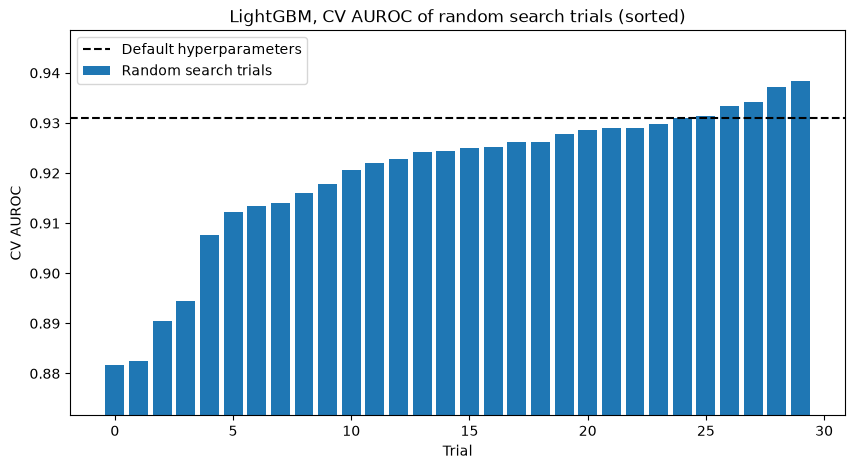

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(trial_scores)), trial_scores, label="Random search trials")
ax.axhline(default_score, color="black", ls="--", label="Default hyperparameters")
ax.set_ylim(trial_scores.min() - 0.01, trial_scores.max() + 0.01)
ax.set_title("LightGBM, CV AUROC of random search trials (sorted)")
ax.set_xlabel("Trial")
ax.set_ylabel("CV AUROC")
ax.legend()
plt.show()

Różnica między najgorszą i najlepszą próbą to ok. 6 punktów procentowych AUROC - prawie tyle, ile dzieli LightGBM od Random Forest na zbiorze testowym! Boosting jest zatem dość wrażliwy na hiperparametry, a źle dobrane mogą zmarnować jego przewagę. Jednocześnie domyślne hiperparametry LightGBM są bardzo dobre - lepsze od ok. 80% losowych prób, a najlepsza znaleziona konfiguracja jest od nich lepsza o niecały punkt procentowy. Jest to dość typowa sytuacja dla nowoczesnych bibliotek, których domyślne wartości dobrano na bardzo wielu zbiorach danych. Tuning daje zwykle większe zyski dla nietypowych danych, np. bardzo małych lub bardzo dużych zbiorów.

## Tuning progu decyzyjnego

Domyślny próg 50% nie jest zawsze optymalny. Zmieniając go, kontrolujemy kompromis między precyzją a czułością:
- niższy próg - więcej przykładów uznajemy za klasę 1, więc czułość rośnie, a precyzja spada
- wyższy próg - mniej przykładów uznajemy za klasę 1, więc precyzja rośnie, a czułość spada

Próg jest zatem hiperparametrem i możemy go dobrać, np. tak, żeby zmaksymalizować F1-score. Jak każdy hiperparametr, dobieramy go na zbiorze walidacyjnym albo za pomocą walidacji skrośnej, a **nigdy** na zbiorze testowym. Automatyzuje to klasa [TunedThresholdClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html). Opakowuje ona dowolny klasyfikator, w `.fit()` wybiera próg za pomocą walidacji skrośnej i trenuje model na całym zbiorze treningowym, a w `.predict()` używa znalezionego progu (atrybut `.best_threshold_`).

Zrobimy to najpierw dla najlepszej regresji logistycznej, czyli `log_reg_missing`. Zobaczmy, jak precyzja, czułość i F1-score zależą od progu. Prawdopodobieństwa dla zbioru treningowego obliczamy za pomocą walidacji skrośnej ([cross_val_predict()](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)), czyli każda predykcja pochodzi od modelu, który nie widział danego przykładu podczas treningu. Funkcja [precision_recall_curve()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html) oblicza precyzję i czułość dla wszystkich możliwych progów.

In [38]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import TunedThresholdClassifierCV, cross_val_predict

y_proba_cv = cross_val_predict(
    log_reg_missing, X_train, y_train, cv=5, method="predict_proba"
)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, y_proba_cv)
# last values of precision and recall don't have corresponding thresholds
precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

log_reg_tuned = TunedThresholdClassifierCV(
    log_reg_missing, scoring="f1", cv=5, random_state=0
)
log_reg_tuned.fit(X_train, y_train)
best_threshold = log_reg_tuned.best_threshold_

print(f"LR tuned threshold, best threshold: {best_threshold:.2f}")
results["LR tuned threshold"] = evaluate_model(
    log_reg_tuned, X_train, X_test, y_train, y_test
)

LR tuned threshold, best threshold: 0.81
Train AUROC: 92.27%
Test AUROC: 85.46%
Precision: 31.55%
Recall: 43.09%
F1-score: 36.43%


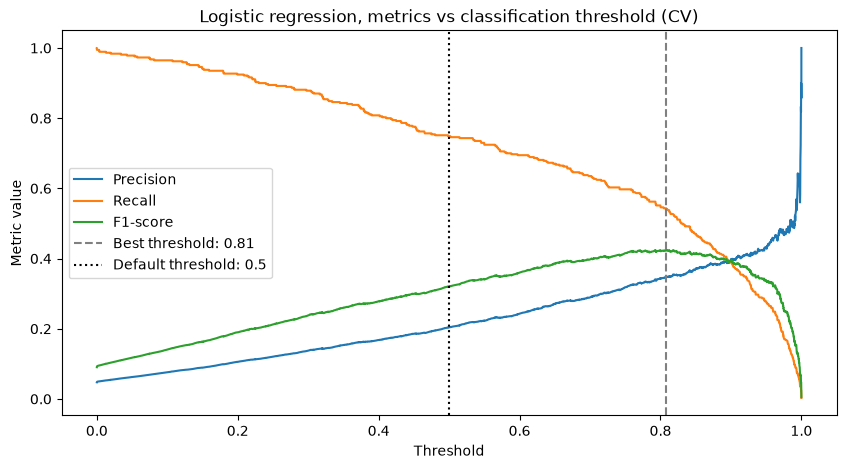

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, precision, label="Precision")
ax.plot(thresholds, recall, label="Recall")
ax.plot(thresholds, f1, label="F1-score")
ax.axvline(
    best_threshold, color="gray", ls="--", label=f"Best threshold: {best_threshold:.2f}"
)
ax.axvline(0.5, color="black", ls=":", label="Default threshold: 0.5")
ax.set_title("Logistic regression, metrics vs classification threshold (CV)")
ax.set_xlabel("Threshold")
ax.set_ylabel("Metric value")
ax.legend()
plt.show()

Najlepszy próg jest wyraźnie wyższy niż 50%. Ma to sens - ważenie klas sztucznie podniosło prawdopodobieństwa klasy 1, więc przy progu 50% mamy bardzo dużo fałszywych alarmów. Tuning progu przesunął kompromis w stronę precyzji, co znacząco poprawiło F1-score. Zwróć uwagę, że AUROC się nie zmienił, bo nie zależy on od progu.

Ważenie klas i tuning progu to dwa sposoby radzenia sobie z tym samym problemem, czyli niezbalansowaniem klas. W praktyce często wystarcza sam tuning progu, bez ważenia klas.

### Zadanie 7 (0.5 punktu)

Dokonaj tuningu progu decyzyjnego, maksymalizując F1-score, dla modelu `rf` w zmiennej `rf_tuned` oraz dla najlepszego modelu LightGBM (`lgbm_search.best_estimator_`) w zmiennej `lgbm_tuned`. Użyj `TunedThresholdClassifierCV` z `cv=5` oraz `random_state=0`. Wypisz najlepsze progi i zapisz wyniki w `results` pod kluczami `"Random Forest tuned threshold"` oraz `"LightGBM tuned threshold"`.

Skomentuj wyniki:
- Czy najlepsze progi są wyższe, czy niższe niż 50%? Dlaczego inaczej niż dla regresji logistycznej?
- Dlaczego próg dla LightGBM jest aż tak niski? Weź pod uwagę AUROC tego modelu na zbiorze treningowym.
- Jak tuning progu zmienił precyzję, czułość i F1-score każdego z trzech algorytmów? Który model jest najlepszy po tuningu progu?

In [40]:
rf_tuned = TunedThresholdClassifierCV(rf, scoring="f1", cv=5, random_state=0)
rf_tuned.fit(X_train, y_train)
print(f"Random Forest, best threshold: {rf_tuned.best_threshold_:.2f}")
results["Random Forest tuned threshold"] = evaluate_model(
    rf_tuned, X_train, X_test, y_train, y_test
)

lgbm_tuned = TunedThresholdClassifierCV(
    lgbm_search.best_estimator_, scoring="f1", cv=5, random_state=0
)
lgbm_tuned.fit(X_train, y_train)
print(f"LightGBM, best threshold: {lgbm_tuned.best_threshold_:.2f}")
results["LightGBM tuned threshold"] = evaluate_model(
    lgbm_tuned, X_train, X_test, y_train, y_test
)


Random Forest, best threshold: 0.24
Train AUROC: 100.00%
Test AUROC: 84.45%
Precision: 48.60%
Recall: 42.28%
F1-score: 45.22%
LightGBM, best threshold: 0.03
Train AUROC: 100.00%
Test AUROC: 91.99%
Precision: 63.55%
Recall: 55.28%
F1-score: 59.13%


In [41]:
assert rf_tuned.best_threshold_ < 0.5
assert results["Random Forest tuned threshold"]["f1"] > results["Random Forest"]["f1"]

assert lgbm_tuned.best_threshold_ < 0.5
assert results["LightGBM tuned threshold"]["f1"] > results["LightGBM tuned"]["f1"]

print("Solution is correct!")

Solution is correct!


Próg regresji wyszedł 0,81, czyli powyżej 50%. Próg lasu to 0,24, a LightGBM 0,03. Regresja była trenowana z wagami klas, które podniosły prawdopodobieństwa bankructwa, więc próg trzeba było podnieść, żeby uciąć fałszywe alarmy. Las i LightGBM szły bez wag. Przy 50% prawie nie krzyczą "bankructwo": czułość to 17,07% i 37,40%. Żeby podnieść F1, próg schodzi w dół.

Próg LightGBM jest tak niski, bo AUROC na treningu wynosi 100%, a przy progu 50% czułość na teście to tylko 37,40%. Model dobrze szereguje firmy, ale samo prawdopodobieństwo bankructwa rzadko dobija do 50%. Najlepsze F1 jest przy progu około 3%.

Po zmianie progu: regresja - precyzja 19,07% -> 31,55%, czułość 69,92% -> 43,09%, F1 29,97% -> 36,43%. Las - precyzja 75,00% -> 48,60%, czułość 17,07% -> 42,28%, F1 27,81% -> 45,22%. LightGBM - precyzja 85,19% -> 63,55%, czułość 37,40% -> 55,28%, F1 51,98% -> 59,13%. AUROC się nie rusza, bo nie zależy od progu. Po tuningu progu najlepszy jest LightGBM.

## Porównanie modeli

Wytrenowaliśmy sporo modeli, więc porównajmy je na wspólnych wykresach. Najpierw narysujmy krzywe ROC kilku najlepszych modeli z każdej grupy, za pomocą klasy [RocCurveDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html).

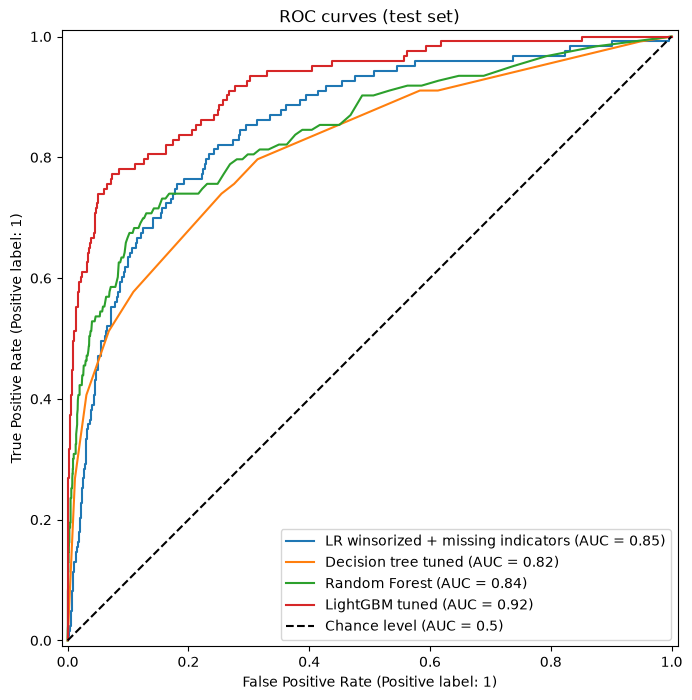

In [42]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 8))
roc_models = {
    "LR winsorized + missing indicators": log_reg_missing,
    "Decision tree tuned": tree_grid,
    "Random Forest": rf,
    "LightGBM tuned": lgbm_search,
}
for i, (name, model) in enumerate(roc_models.items()):
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax,
        plot_chance_level=(i == len(roc_models) - 1),
    )
ax.set_title("ROC curves (test set)")
plt.show()

Teraz porównajmy wszystkie modele. Ta funkcja przyda się także w drugiej części laboratorium.

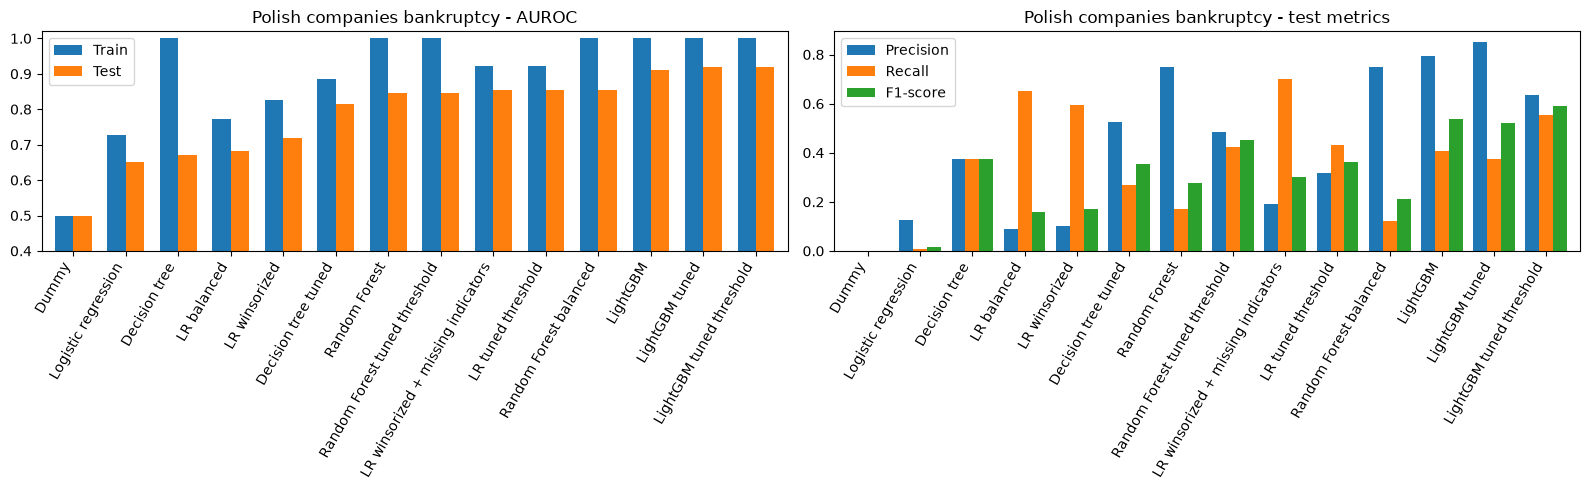

,train_auroc,test_auroc,precision,recall,f1
Dummy,0.500,0.500,0.000,0.000,0.000
Logistic regression,0.728,0.652,0.125,0.008,0.015
Decision tree,1.000,0.671,0.374,0.374,0.374
LR balanced,0.773,0.682,0.090,0.650,0.158
LR winsorized,0.826,0.719,0.100,0.593,0.172
Decision tree tuned,0.885,0.816,0.524,0.268,0.355
Random Forest,1.000,0.845,0.750,0.171,0.278
Random Forest tuned threshold,1.000,0.845,0.486,0.423,0.452
LR winsorized + missing indicators,0.923,0.855,0.191,0.699,0.300
LR tuned threshold,0.923,0.855,0.315,0.431,0.364


In [43]:
def plot_results(results: dict[str, dict[str, float]], title: str) -> None:
    results_df = pd.DataFrame(results).T.sort_values("test_auroc")

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    results_df[["train_auroc", "test_auroc"]].plot.bar(ax=axes[0], width=0.7)
    axes[0].set_title(f"{title} - AUROC")
    axes[0].set_ylim(0.4, 1.02)
    axes[0].legend(["Train", "Test"])

    results_df[["precision", "recall", "f1"]].plot.bar(ax=axes[1], width=0.8)
    axes[1].set_title(f"{title} - test metrics")
    axes[1].legend(["Precision", "Recall", "F1-score"])

    for ax in axes:
        ax.tick_params(axis="x", rotation=60)
        for label in ax.get_xticklabels():
            label.set_horizontalalignment("right")
    plt.tight_layout()
    plt.show()


plot_results(results, "Polish companies bankruptcy")
pd.DataFrame(results).T.sort_values("test_auroc").round(3)

Krzywa ROC LightGBM jest prawie wszędzie powyżej pozostałych, a różnica w AUROC jest bardzo wyraźna. Boosting jest tutaj zdecydowanie najlepszym modelem, co jest bardzo typowe dla danych tabelarycznych. Ciekawe jest też to, że regresja logistyczna z dobrym przetwarzaniem danych może konkurować z modelami drzewiastymi, o ile mamy dobre zrozumienie danych.

Zwróć uwagę, jak bardzo próg decyzyjny wpływa na precyzję, czułość i F1-score, nawet przy podobnym AUROC.

## Ważność cech

Wiemy już, które modele działają najlepiej, ale na czym opierają one swoje decyzje? Jest to pytanie o **interpretowalność (interpretability)** modelu. Jest ona ważna z kilku powodów:
- **wymogi prawne** - np. bank musi być w stanie uzasadnić odmowę udzielenia kredytu
- **zaufanie i wiedza dziedzinowa** - eksperci (np. ekonomiści) chcą wiedzieć, czy model korzysta z sensownych przesłanek, a czasami wiedza o tym, co jest ważne, jest dla nich cenniejsza niż sam model
- **debugowanie modelu** - ważność cech może pokazać np. wyciek danych albo błędy w przetwarzaniu

Sprawdzimy globalną **ważność cech (feature importance)**, czyli to, jak mocno model opiera się na poszczególnych cechach, dla wszystkich trzech rodzajów modeli.

### Wagi regresji logistycznej

W laboratorium 1 interpretowaliśmy wagi modeli liniowych. Jeżeli cechy są przeskalowane, np. standaryzacją, to wartość bezwzględna wagi mówi, jak mocno zmienia się predykcja modelu, gdy cecha zmienia się o jedno odchylenie standardowe. Znak wagi mówi natomiast o kierunku: dodatnia waga oznacza, że wyższa wartość cechy zwiększa prawdopodobieństwo bankructwa. Wagi znajdują się w atrybucie `.coef_` modelu, a nazwy cech po przetwarzaniu zwraca metoda `.get_feature_names_out()` pipeline'u bez ostatniego kroku (modelu).

### Ważność cech w modelach drzewiastych

Każdy podział w drzewie korzysta z jednej cechy i zmniejsza nieczystość (np. entropię) o pewną wartość. Sumując te redukcje dla wszystkich podziałów korzystających z danej cechy, ważąc je liczbą przykładów w węzłach, i uśredniając po wszystkich drzewach w zespole, dostajemy **Mean Decrease in Impurity (MDI)**. W scikit-learn jest to atrybut `.feature_importances_`, znormalizowany tak, żeby wartości sumowały się do 1.

LightGBM oferuje dwa typy ważności cech:
- `"split"` - liczba podziałów, w których cecha została wykorzystana (domyślny w `.feature_importances_`)
- `"gain"` - łączna redukcja funkcji kosztu przez podziały z daną cechą, czyli odpowiednik MDI; obliczymy ją za pomocą `.booster_.feature_importance(importance_type="gain")`

Ważności w LightGBM nie są znormalizowane, więc dla porównania podzielimy je przez sumę.

Taka ważność cech ma jednak wady:
- jest obliczana na zbiorze treningowym, więc może odzwierciedlać przeuczenie, a nie to, co faktycznie pomaga w predykcji na nowych danych
- jest **obciążona w stronę cech o wielu unikalnych wartościach (high cardinality)**, np. ciągłych - mają one dużo więcej możliwych progów podziału, więc częściej znajdą dobry podział, nawet przypadkowo

### Ważność cech dla naszych modeli

Obliczmy teraz ważność cech dla najlepszych modeli z każdej grupy: regresji logistycznej `log_reg_missing` (wartości bezwzględne wag), Random Forest `rf` (MDI) oraz najlepszego modelu LightGBM (gain, znormalizowany tak, żeby sumował się do 1). Wskaźniki brakujących wartości mają w pipeline'ie nazwy z prefiksem `missingindicator_`, więc nazwiemy je np. `"missing: net profit / total assets"`. Wszystkie ważności narysujemy funkcją `plot_importances()`, która przyda się także w drugiej części laboratorium.

In [44]:
def plot_importances(importances: pd.Series, title: str, n: int = 15) -> None:
    top_importances = importances.nlargest(n).sort_values()
    ax = top_importances.plot.barh(figsize=(8, 6))
    ax.set_title(title)
    ax.set_xlabel("Importance")
    plt.show()


# logistic regression weights, missing indicators have names with prefix
lr_names = [
    feature_names[name]
    if name in feature_names
    else "missing: " + feature_names[name.removeprefix("missingindicator_")]
    for name in log_reg_missing[:-1].get_feature_names_out()
]
importances_lr = pd.Series(log_reg_missing[-1].coef_[0], index=lr_names).abs()

names = X_train.columns.map(feature_names)

importances_rf = pd.Series(rf.feature_importances_, index=names)

best_lgbm = lgbm_search.best_estimator_
importances_lgbm = pd.Series(
    best_lgbm.booster_.feature_importance(importance_type="gain"), index=names
)
importances_lgbm = importances_lgbm / importances_lgbm.sum()

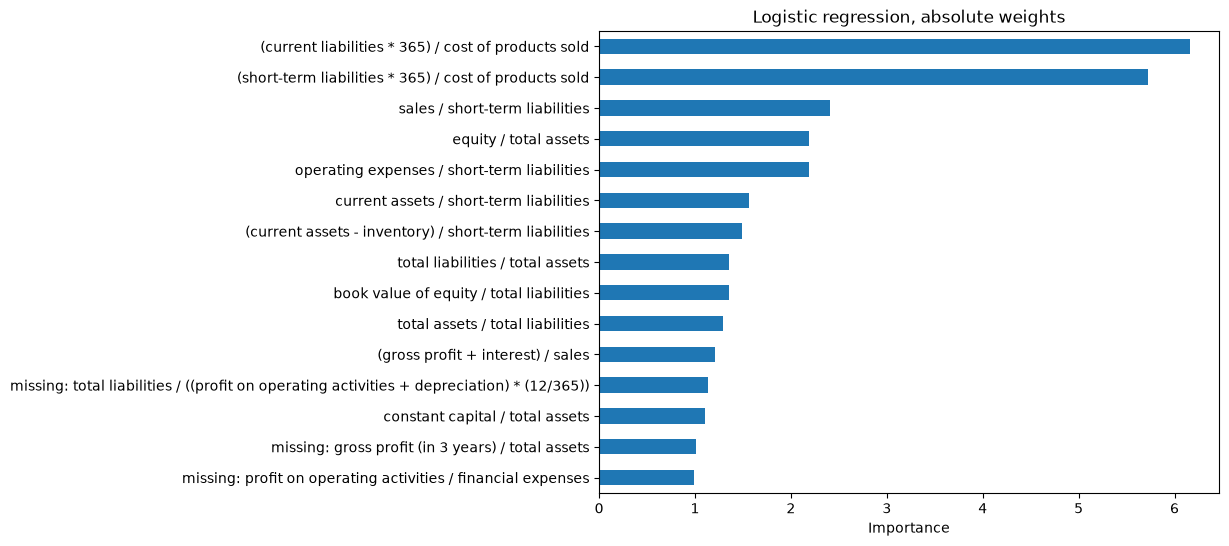

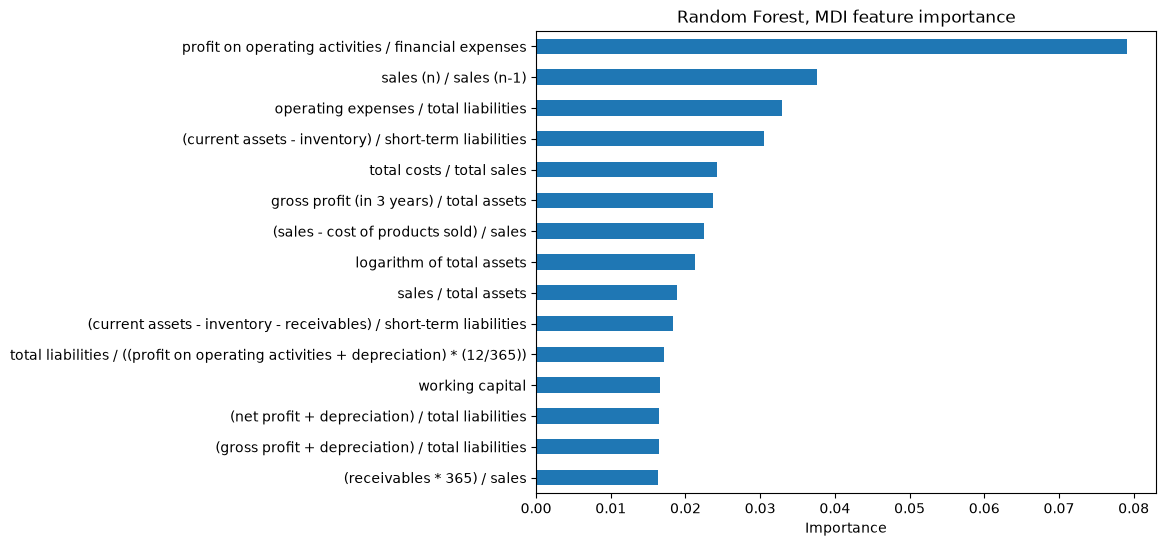

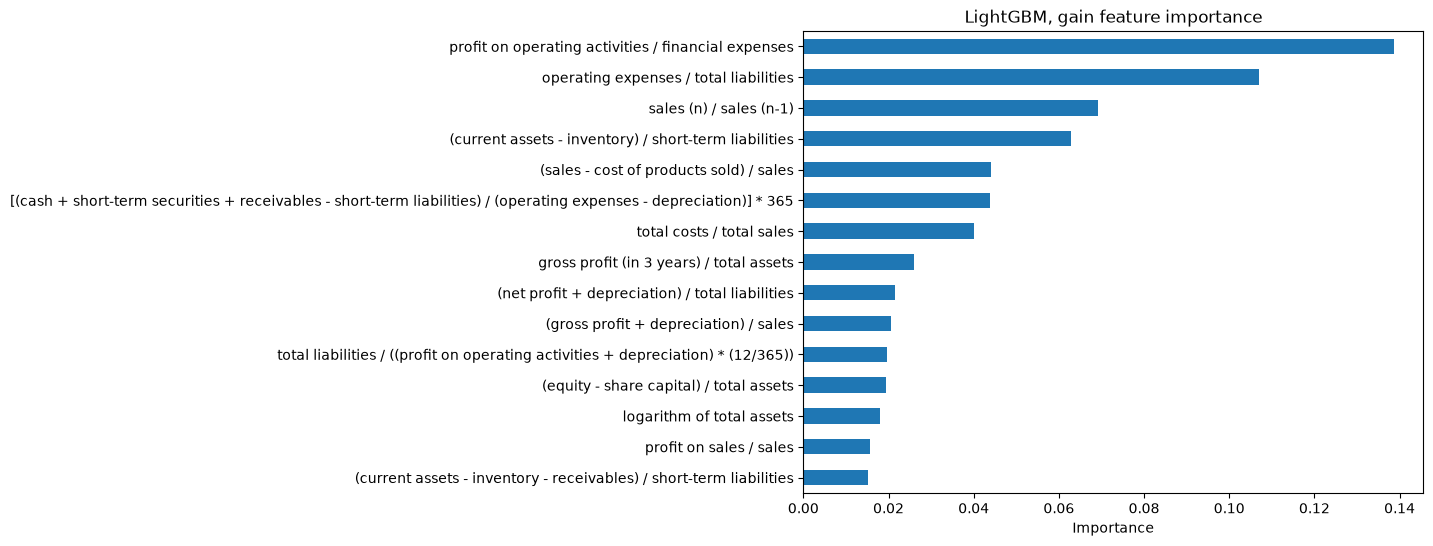

In [45]:
plot_importances(importances_lr, "Logistic regression, absolute weights")
plot_importances(importances_rf, "Random Forest, MDI feature importance")
plot_importances(importances_lgbm, "LightGBM, gain feature importance")

Random Forest i LightGBM są w dużej mierze zgodne. Najważniejszą cechą jest dla nich `Attr27` (`profit on operating activities / financial expenses`), a w czołówce jest też `Attr21` (`sales (n) / sales (n-1)`). To dokładnie te dwie cechy, dla których podczas EDA znaleźliśmy informatywne wartości brakujące! Drzewa w scikit-learn oraz LightGBM obsługują braki natywnie, więc wykorzystują zarówno wartość wskaźnika, jak i sam fakt jego braku - widzieliśmy to już w podziałach z progiem `inf` w drzewie po tuningu. W regresji logistycznej tę informację niosą wskaźniki brakujących wartości, które również pojawiają się wśród cech o dużych wagach, np. dla `Attr27`.

Ciekawe są natomiast dwie największe wagi regresji logistycznej. Cechy `Attr32` (`(current liabilities * 365) / cost of products sold`) i `Attr52` (`(short-term liabilities * 365) / cost of products sold`) to praktycznie ten sam wskaźnik - po winsoryzacji ich korelacja wynosi 0.99. Mają one ogromne wagi o przeciwnych znakach (ok. +6.2 i -5.7), które w dużej mierze się znoszą. Jest to typowy efekt **współliniowości (collinearity)**: dla prawie identycznych cech model może niemal dowolnie "przelewać" wagę między nimi, więc pojedyncze wagi są niestabilne i nie da się ich interpretować osobno. Dlatego wagi modeli liniowych trzeba interpretować ostrożnie, szczególnie w danych finansowych, gdzie wiele wskaźników jest do siebie bardzo podobnych.

## Zbiór danych Hotel booking demand

Teraz Twoja kolej, żeby samodzielnie przeprowadzić cały proces na drugim zbiorze danych. Wykorzystamy zbiór [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand), opisany w [tym artykule](https://doi.org/10.1016/j.dib.2018.11.126) (Antonio, de Almeida, Nunes, 2019), licencja CC BY 4.0. Zawiera on rezerwacje hotelu wypoczynkowego w regionie Algarve (Portugalia), z datami przyjazdu od lipca 2015 do sierpnia 2017. Zadaniem jest przewidywanie, czy rezerwacja zostanie anulowana (kolumna `is_canceled`).

Jest to bardzo praktyczny problem. Hotele często stosują **overbooking**, czyli sprzedają więcej pokoi, niż mają, licząc na to, że część gości anuluje rezerwację. Dobre przewidywanie anulacji pozwala lepiej planować obłożenie i ceny.

Opisy wszystkich kolumn znajdują się w pliku [hotel_description.txt](hotel_description.txt), a dane w pliku [hotel_data.csv.gz](hotel_data.csv.gz).

Ten zbiór dość mocno różni się od poprzedniego. Ma kilka razy więcej próbek, a przede wszystkim ma różne typy cech: numeryczne, kategoryczne (także o bardzo wielu wartościach, np. kraj pochodzenia gościa), z wartościami brakującymi. Ma też kilka pułapek, które musisz uwzględnić.

### Wyciek danych

Niektóre kolumny zawierają informacje, których nie znalibyśmy w momencie predykcji. Jest to **wyciek danych (data leakage)** - model z takimi cechami może mieć prawie idealne wyniki, ale jest kompletnie bezużyteczny w praktyce. W tym zbiorze są to:
- `reservation_status` - ostateczny status rezerwacji (`Canceled`, `Check-Out`, `No-Show`), czyli praktycznie zmienna docelowa
- `reservation_status_date` - data ustawienia tego statusu, czyli np. data anulacji
- `assigned_room_type` - typ pokoju przydzielonego gościowi, ustalany przy zameldowaniu; anulowane rezerwacje prawie zawsze mają po prostu zarezerwowany typ pokoju
- `booking_changes` - liczba zmian w rezerwacji, liczona aż do zameldowania lub anulacji, czyli też częściowo z przyszłości

Przy każdej cesze warto zadać sobie pytanie: czy w momencie, w którym chcę użyć modelu, będę znał jej wartość?

### Przetwarzanie danych dla różnych modeli

Różne modele wymagają zupełnie innego przetwarzania danych:
- **regresja logistyczna** - cechy numeryczne wymagają imputacji i skalowania, a kategoryczne - kodowania one-hot encoding
- **Random Forest** w scikit-learn - obsługuje wartości brakujące, ale nie obsługuje zmiennych kategorycznych; wystarczy jednak zakodować je kolejnymi liczbami całkowitymi (*ordinal encoding*); dla drzew nie jest to dużym problemem, nawet dla zmiennych nominalnych, bo kilka kolejnych podziałów może wyodrębnić dowolną kategorię
- **LightGBM** - obsługuje natywnie zarówno wartości brakujące, jak i zmienne kategoryczne o typie `category` z Pandasa, więc nie wymaga żadnego przetwarzania; przy podziale względem zmiennej kategorycznej szuka najlepszego podziału kategorii na dwie grupy

Różne transformacje dla różnych grup kolumn łączy klasa [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), którą najwygodniej tworzyć funkcją [make_column_transformer()](https://scikit-learn.org/stable/modules/generated/sklearn.compose.make_column_transformer.html). Przyjmuje ona pary (transformacja, lista kolumn), a wyniki łączy wzdłuż kolumn, tak jak robiliśmy to ręcznie za pomocą `pd.concat()` w laboratorium 1. Kolumny, których nie wymieniliśmy, są domyślnie usuwane, ale z `remainder="passthrough"` są przekazywane bez zmian. Argument `verbose_feature_names_out=False` zapobiega dodawaniu nazw transformacji jako prefiksów do nazw cech. Przykładowo:

```python
from sklearn.compose import make_column_transformer

preprocessing = make_column_transformer(
    (make_pipeline(SimpleImputer(), StandardScaler()), numerical_features),
    (OneHotEncoder(sparse_output=False), categorical_features),
    verbose_feature_names_out=False,
)
model = make_pipeline(preprocessing, LogisticRegression(solver="newton-cholesky"))
```

Przydatne opcje kodowania zmiennych kategorycznych:
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) traktuje wartości brakujące jako osobną kategorię; argument `min_frequency` łączy rzadkie kategorie w jedną kategorię `"infrequent"`, co jest bardzo przydatne np. dla krajów, a `handle_unknown="infrequent_if_exist"` koduje kategorie nieznane ze zbioru treningowego jako tę kategorię
- [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html) z argumentami `handle_unknown="use_encoded_value"`, `unknown_value=-1` oraz `encoded_missing_value=-1` koduje nieznane kategorie oraz wartości brakujące jako -1

LightGBM korzysta bezpośrednio z oryginalnych kolumn, także kategorycznych, więc jego ważność cech jest łatwa do interpretacji - dostajemy jedną wartość dla każdej kolumny, a nie np. kilkadziesiąt osobnych cech po one-hot encoding.

### Zadanie 8 (2 punkty)

Poniższy kod wczytuje dane, usuwa kolumny z wyciekiem danych oraz kolumnę `company` (ponad 90% wartości brakujących), a także zamienia kolumnę `agent` na napisy. Jest to identyfikator biura podróży, czyli zmienna kategoryczna, a nie liczba. Pośredni typ `Int64` zapobiega końcówkom `.0`, a brakujące wartości stają się napisem `"<NA>"`, oznaczającym rezerwację bez biura podróży.

1. Wypisz liczbę próbek i kolumn w `df_hotel` oraz informacje o kolumnach za pomocą `.info()`.
2. Usuń duplikaty i wypisz, ile ich było. Zastanów się, skąd mogą się one tutaj brać.
3. Wyodrębnij kolumnę `is_canceled` do zmiennej `y_hotel` i narysuj rozkład klas, tak jak w zadaniu 1.
4. Narysuj obok siebie dwa wykresy słupkowe z odsetkiem anulowanych rezerwacji (w procentach) dla każdej wartości `deposit_type` oraz `market_segment`.
5. Zapisz listy nazw cech kategorycznych i numerycznych w zmiennych `categorical_features_hotel` oraz `numerical_features_hotel`. Zamień typ cech kategorycznych na `"category"`.
6. Podziel dane na zbiór treningowy i testowy w proporcjach 75%-25%, ze stratyfikacją i `random_state=0`. Użyj zmiennych `X_hotel_train`, `X_hotel_test`, `y_hotel_train` oraz `y_hotel_test`.

Skomentuj wyniki. Skąd mogą brać się duplikaty? Co zaobserwowałeś dla `deposit_type` - czy jest to intuicyjne?

Przydatne metody: `.groupby()` (np. `y_hotel.groupby(df_hotel["deposit_type"]).mean()`), `plt.subplots()`.

In [46]:
leaky_columns = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
]

df_hotel = pd.read_csv("hotel_data.csv.gz")
df_hotel = df_hotel.drop(columns=leaky_columns + ["company"])
df_hotel["agent"] = df_hotel["agent"].astype("Int64").astype(str)

In [47]:
print(f"Samples: {len(df_hotel)}, columns: {df_hotel.shape[1]}")
df_hotel.info()

n_duplicates_hotel = df_hotel.duplicated().sum()
df_hotel = df_hotel.drop_duplicates()
print(f"Duplicates: {n_duplicates_hotel}")

y_hotel = df_hotel.pop("is_canceled")
class_pct_hotel = y_hotel.value_counts(normalize=True).mul(100).sort_index()
print(class_pct_hotel)

for col in ["deposit_type", "market_segment"]:
    print(df_hotel[col].value_counts())
    print(y_hotel.groupby(df_hotel[col]).mean().mul(100))

categorical_features_hotel = [
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "customer_type",
]
numerical_features_hotel = [
    col for col in df_hotel.columns if col not in categorical_features_hotel
]
df_hotel[categorical_features_hotel] = df_hotel[categorical_features_hotel].astype(
    "category"
)

X_hotel_train, X_hotel_test, y_hotel_train, y_hotel_test = train_test_split(
    df_hotel, y_hotel, test_size=0.25, random_state=0, stratify=y_hotel
)


Samples: 40060, columns: 26
<class 'pandas.DataFrame'>
RangeIndex: 40060 entries, 0 to 40059
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   is_canceled                     40060 non-null  int64  
 1   lead_time                       40060 non-null  int64  
 2   arrival_date_year               40060 non-null  int64  
 3   arrival_date_month              40060 non-null  str    
 4   arrival_date_week_number        40060 non-null  int64  
 5   arrival_date_day_of_month       40060 non-null  int64  
 6   stays_in_weekend_nights         40060 non-null  int64  
 7   stays_in_week_nights            40060 non-null  int64  
 8   adults                          40060 non-null  int64  
 9   children                        40060 non-null  float64
 10  babies                          40060 non-null  int64  
 11  meal                            40060 non-null  str    
 12  country        

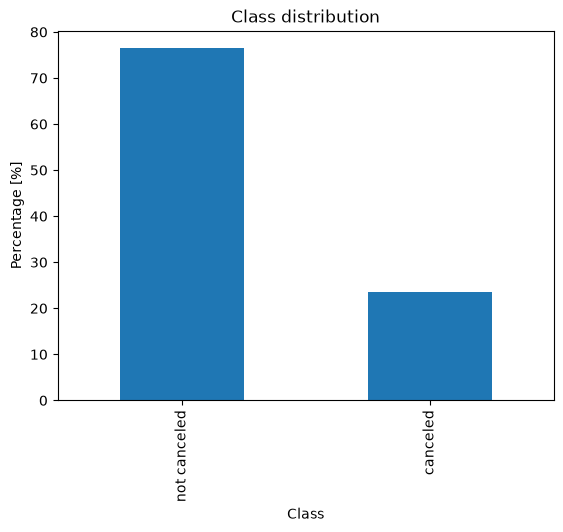

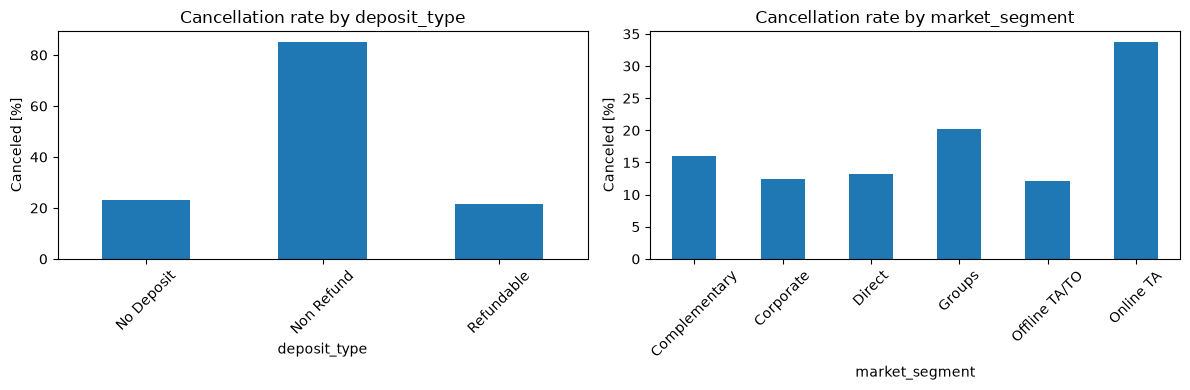

In [48]:
ax = class_pct_hotel.rename({0: "not canceled", 1: "canceled"}).plot.bar()
ax.set_title("Class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage [%]")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["deposit_type", "market_segment"]):
    rates = y_hotel.groupby(df_hotel[col], observed=True).mean().mul(100)
    rates.plot.bar(ax=ax)
    ax.set_title(f"Cancellation rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Canceled [%]")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


In [49]:
assert df_hotel.shape == (33224, 25)
assert not set(leaky_columns + ["company"]) & set(df_hotel.columns)
assert "is_canceled" not in df_hotel.columns
assert 23 < y_hotel.mean() * 100 < 24

assert set(categorical_features_hotel) == {
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "customer_type",
}
assert len(numerical_features_hotel) == 16
assert (df_hotel[categorical_features_hotel].dtypes == "category").all()
assert "240" in df_hotel["agent"].cat.categories

assert X_hotel_train.shape == (24918, 25)
assert X_hotel_test.shape == (8306, 25)

print("Solution is correct!")

Solution is correct!


Na starcie jest 40060 wierszy i 26 kolumn. Duplikatów jest 6836, zostaje 33224 rezerwacje. Anulowanych jest 23,57%.

Duplikaty mogą brać się stąd, że z danych wycięto informacje o konkretnym gościu. Dwie różne osoby z tego samego kraju, z tym samym terminem, pokojem i biurem podróży, wyglądają jak jeden wiersz. Może też ten sam rekord wpaść do pliku dwa razy. Bez danych osobowych identyczne rezerwacje nie są niemożliwe.

deposit_type nie wygląda intuicyjnie. Non Refund ma 85,06% anulacji, No Deposit 23,25%, a Refundable 21,62%. Bezzwrotna wpłata powinna raczej zniechęcać do anulowania, a tu odsetek jest najwyższy. Tych rezerwacji jest mało (174 Non Refund i 74 Refundable przy 32976 bez wpłaty), ale różnica jest duża.


### Zadanie 9 (2 punkty)

1. Stwórz i wytrenuj trzy modele, korzystając z pipeline'ów:
    - `log_reg_hotel` - regresja logistyczna z `class_weight="balanced"` i `solver="newton-cholesky"`; cechy numeryczne: imputacja medianą i standaryzacja; cechy kategoryczne: `OneHotEncoder` z `handle_unknown="infrequent_if_exist"`, `min_frequency=20` oraz `sparse_output=False`,
    - `rf_hotel` - Random Forest z 500 drzewami, `n_jobs=-1` i `random_state=0`; cechy kategoryczne: `OrdinalEncoder` kodujący nieznane i brakujące wartości jako -1, cechy numeryczne bez zmian,
    - `lgbm_hotel` - LightGBM z domyślnymi hiperparametrami, `random_state=0` i `verbose=-1`, bez żadnego przetwarzania.
2. Dokonaj ewaluacji modeli i zapisz wyniki w słowniku `results_hotel`, pod kluczami `"Logistic regression"`, `"Random Forest"` oraz `"LightGBM"`. Porównaj modele za pomocą `plot_results()`.
3. Dokonaj tuningu progu decyzyjnego dla modelu LightGBM (`lgbm_hotel_tuned`), tak jak w zadaniu 7. Zapisz wyniki pod kluczem `"LightGBM tuned threshold"`.

Skomentuj wyniki:
- Który model jest najlepszy? Czy któryś z modeli jest przeuczony?
- Porównaj, jakiego przetwarzania danych wymagał każdy z modeli. Który był najwygodniejszy?
- Jak tuning progu zmienił precyzję i czułość? Który wariant wybrałbyś dla hotelu, który chce stosować overbooking?

In [50]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

results_hotel = {}

log_reg_hotel = make_pipeline(
    make_column_transformer(
        (
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
            numerical_features_hotel,
        ),
        (
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=20,
                sparse_output=False,
            ),
            categorical_features_hotel,
        ),
        verbose_feature_names_out=False,
    ),
    LogisticRegression(class_weight="balanced", solver="newton-cholesky"),
)

rf_hotel = make_pipeline(
    make_column_transformer(
        (
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
            ),
            categorical_features_hotel,
        ),
        ("passthrough", numerical_features_hotel),
        verbose_feature_names_out=False,
    ),
    RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0),
)

lgbm_hotel = LGBMClassifier(random_state=0, verbose=-1)

for name, model in [
    ("Logistic regression", log_reg_hotel),
    ("Random Forest", rf_hotel),
    ("LightGBM", lgbm_hotel),
]:
    model.fit(X_hotel_train, y_hotel_train)
    print(name)
    results_hotel[name] = evaluate_model(
        model, X_hotel_train, X_hotel_test, y_hotel_train, y_hotel_test
    )
    print()

lgbm_hotel_tuned = TunedThresholdClassifierCV(
    lgbm_hotel, scoring="f1", cv=5, random_state=0
)
lgbm_hotel_tuned.fit(X_hotel_train, y_hotel_train)
print(f"LightGBM, best threshold: {lgbm_hotel_tuned.best_threshold_:.2f}")
results_hotel["LightGBM tuned threshold"] = evaluate_model(
    lgbm_hotel_tuned, X_hotel_train, X_hotel_test, y_hotel_train, y_hotel_test
)


Logistic regression
Train AUROC: 90.04%
Test AUROC: 89.23%
Precision: 55.42%
Recall: 84.36%
F1-score: 66.90%

Random Forest
Train AUROC: 100.00%
Test AUROC: 93.45%
Precision: 77.70%
Recall: 70.31%
F1-score: 73.82%

LightGBM
Train AUROC: 96.44%
Test AUROC: 94.24%
Precision: 77.04%
Recall: 73.22%
F1-score: 75.09%

LightGBM, best threshold: 0.39
Train AUROC: 96.44%
Test AUROC: 94.24%
Precision: 72.12%
Recall: 81.14%
F1-score: 76.36%


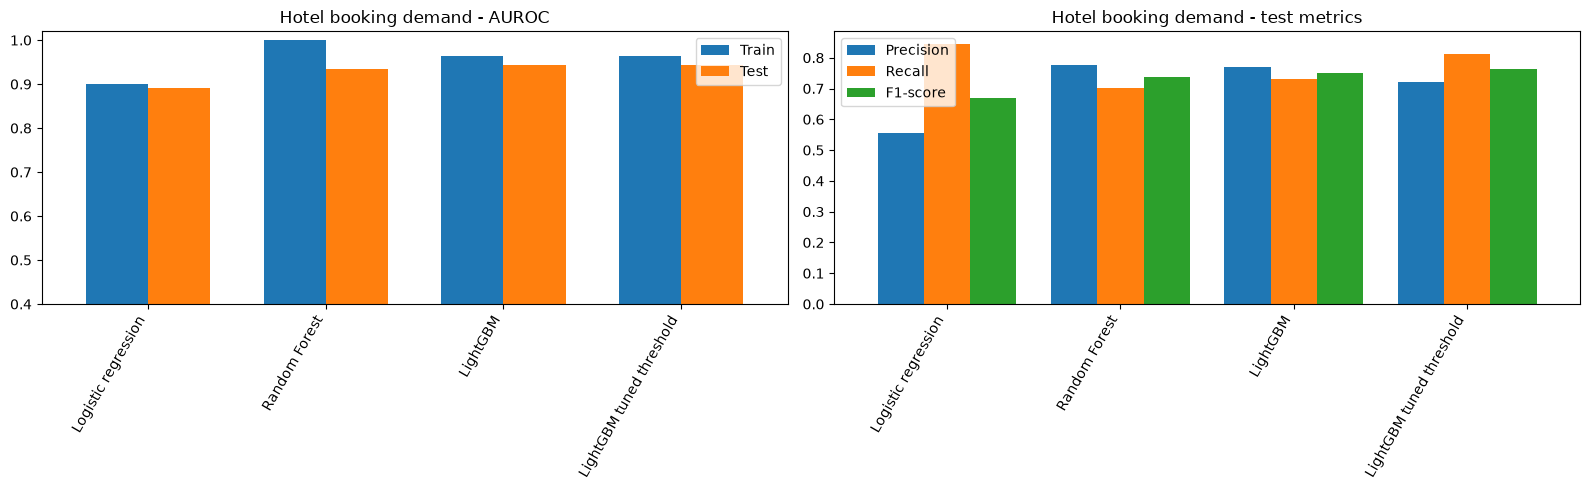

In [51]:
plot_results(results_hotel, "Hotel booking demand")


In [52]:
for name in ["Logistic regression", "Random Forest", "LightGBM"]:
    assert results_hotel[name]["test_auroc"] > 0.87

assert results_hotel["LightGBM"]["test_auroc"] > 0.93
assert (
    results_hotel["LightGBM"]["test_auroc"]
    > results_hotel["Logistic regression"]["test_auroc"]
)

assert lgbm_hotel_tuned.best_threshold_ < 0.5
assert (
    results_hotel["LightGBM tuned threshold"]["recall"]
    > results_hotel["LightGBM"]["recall"]
)

print("Solution is correct!")

Solution is correct!


Najlepszy jest LightGBM, test AUROC 94,24%. Las ma 93,45%, regresja 89,23%. Las ma 100% na treningu i 93,45% na teście, więc jest trochę przeuczony, ale test i tak jest wysoki. LightGBM ma 96,44% i 94,24%, różnica jest mała. Regresja 90,04% i 89,23%, przeuczenia prawie nie widać.

Regresja potrzebowała imputacji, standaryzacji i one-hot. Las tylko zamiany kategorii na liczby, kolumny numeryczne szły bez zmian. LightGBM wziął dane tak jak są, razem z typem category. Najwygodniejszy był LightGBM i przy okazji najlepszy.

Próg LightGBM spadł do 0,39. Precyzja z 77,04% do 72,12%, czułość z 73,22% do 81,14%. Do overbookingu wziąłbym ten niższy próg: łapie 81% anulacji zamiast 73%, więc wiadomo, które pokoje można sprzedać drugi raz. Fałszywych alarmów jest trochę więcej, precyzja spada o około 5 punktów.


### Zadanie 10 (1 punkt)

Oblicz ważność cech dla modeli z zadania 9, tak jak w części o ważności cech, i narysuj je za pomocą `plot_importances()`:
- `importances_hotel_lr` - wartości bezwzględne wag modelu `log_reg_hotel`,
- `importances_hotel_rf` - MDI dla modelu `rf_hotel`,
- `importances_hotel_lgbm` - gain dla modelu `lgbm_hotel`, znormalizowany tak, żeby sumował się do 1.

Wszystkie ważności zapisz jako `pd.Series`, z nazwami cech jako indeksem. Nazwy cech na wejściu modelu zwraca metoda `.get_feature_names_out()` pipeline'u bez ostatniego kroku. Uważaj - `ColumnTransformer` zmienia kolejność kolumn, a `OneHotEncoder` tworzy osobną cechę dla każdej kategorii.

Skomentuj wyniki:
- Które cechy są najważniejsze i czy ma to sens? Czy modele są zgodne?
- Regresja logistyczna ma osobną wagę dla każdej kategorii po one-hot encoding. Jak to utrudnia porównanie jej ważności cech z modelami drzewiastymi?
- Dlaczego rok przyjazdu (`arrival_date_year`) może być ważną cechą? Czy jest to problem, jeżeli chcemy używać modelu dla przyszłych rezerwacji?

In [53]:
importances_hotel_lr = pd.Series(
    np.abs(log_reg_hotel[-1].coef_[0]),
    index=log_reg_hotel[:-1].get_feature_names_out(),
)

importances_hotel_rf = pd.Series(
    rf_hotel[-1].feature_importances_,
    index=rf_hotel[:-1].get_feature_names_out(),
)

importances_hotel_lgbm = pd.Series(
    lgbm_hotel.booster_.feature_importance(importance_type="gain"),
    index=lgbm_hotel.booster_.feature_name(),
)
importances_hotel_lgbm = importances_hotel_lgbm / importances_hotel_lgbm.sum()

print(y_hotel.groupby(df_hotel["arrival_date_year"], observed=True).mean().mul(100))


arrival_date_year
2015    19.136364
2016    21.879502
2017    28.412894
Name: is_canceled, dtype: float64


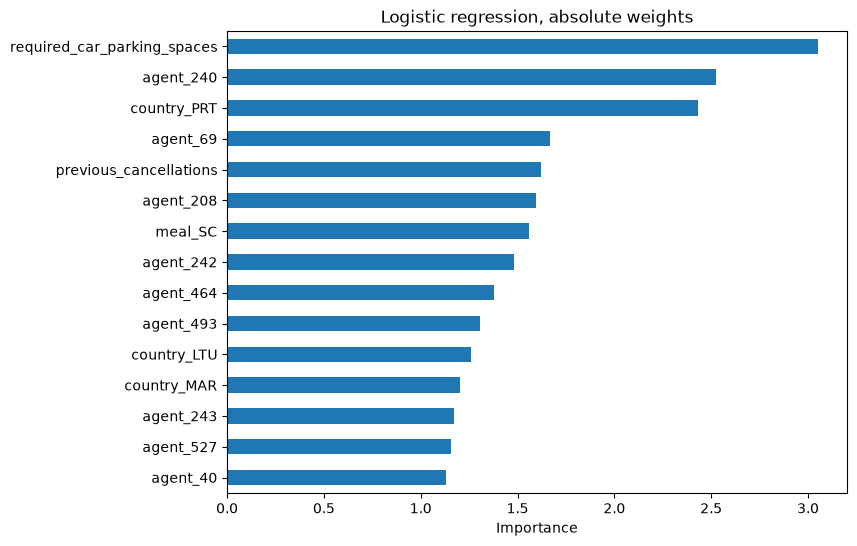

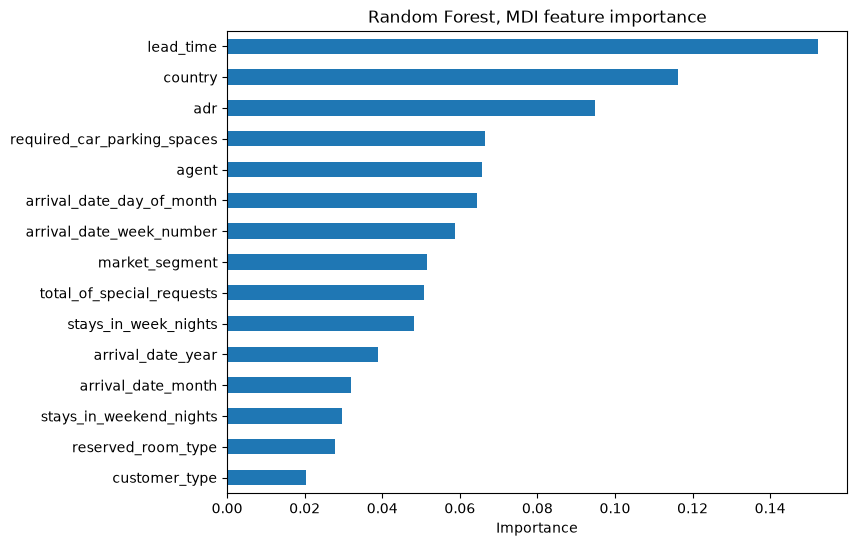

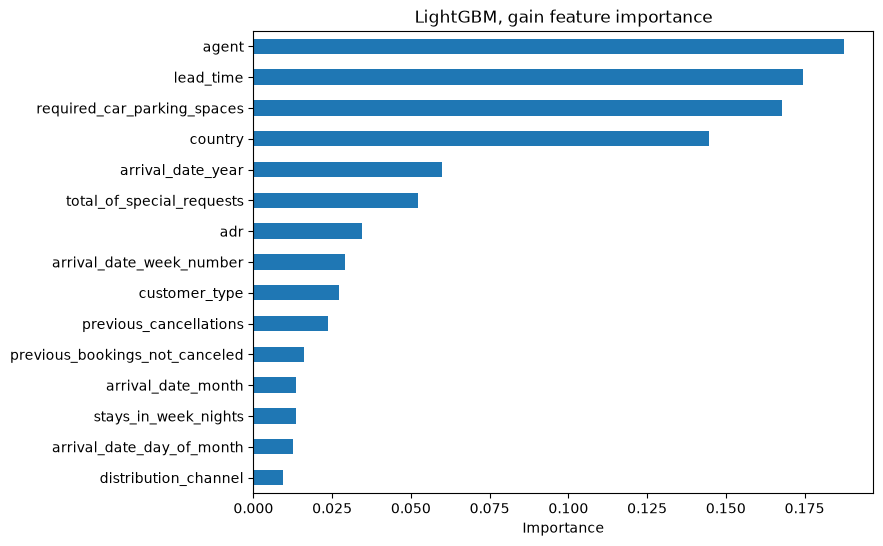

In [54]:
plot_importances(importances_hotel_lr, "Logistic regression, absolute weights")
plot_importances(importances_hotel_rf, "Random Forest, MDI feature importance")
plot_importances(importances_hotel_lgbm, "LightGBM, gain feature importance")


In [55]:
for importances in [importances_hotel_lr, importances_hotel_rf, importances_hotel_lgbm]:
    assert isinstance(importances, pd.Series)
    assert (importances >= 0).all()

assert len(importances_hotel_lr) == log_reg_hotel[-1].coef_.shape[1]
assert (
    len(importances_hotel_rf) == len(importances_hotel_lgbm) == X_hotel_train.shape[1]
)
assert set(importances_hotel_rf.index) == set(X_hotel_train.columns)
assert np.isclose(importances_hotel_rf.sum(), 1)
assert np.isclose(importances_hotel_lgbm.sum(), 1)
assert "country" in importances_hotel_lgbm.nlargest(5).index

print("Solution is correct!")

Solution is correct!


W lesie najwięcej wnoszą lead_time (0,15), country (0,12), adr (0,09), a potem required_car_parking_spaces i agent (po około 0,07). W LightGBM na górze są agent (0,19), lead_time (0,17), required_car_parking_spaces (0,17) i country (0,14). To ma sens: ile dni wcześniej padła rezerwacja, skąd jest gość, które biuro ją zrobiło i czy prosi o parking. Drzewa są zgodne co do czołówki, kolejność się trochę różni. Regresja za największą wagę ma required_car_parking_spaces, około -3,05, czyli prośba o parking obniża szansę anulacji. Dalej są pojedyncze biura (agent_240 w górę, agent_69 w dół) i country_PRT.

Przez one-hot regresja ma osobną wagę dla każdego kraju i każdego agenta, łącznie 152 cechy. W drzewach country i agent to jedna kolumna. Wagi country_PRT nie da się postawić obok ważności country z lasu i uznać, że to to samo. Jedno biuro może mieć ogromną wagę, a w drzewie cała kolumna agent rozkłada się na wiele podziałów.

arrival_date_year jest 5. cechą w LightGBM (około 6% gain) i 11. w lesie. Udział anulacji rośnie z rokiem: 2015 - 19,14%, 2016 - 21,88%, 2017 - 28,41%. Model widział tylko te trzy lata. Dla rezerwacji z późniejszego roku ta liczba leży poza danymi treningowymi. Jak trend się nie powtórzy, cecha będzie mylić.
